# Clasificación automática de actividad patológica en EEG intracraneal

**Proyecto final · Introducción a la Ciencia de Datos · CICESE**
Luz Marey Lugo Acedo · noviembre de 2026

Este notebook contiene todo el desarrollo del proyecto, en el orden del flujo de trabajo:

1. **Datos**: origen, carga y descripción.
2. **Análisis exploratorio**: qué muestran los datos y qué decisiones se toman a partir de ello.
3. **Preprocesamiento**: transformaciones y partición por paciente, sin fugas de información.
4. **Modelado**: líneas base, siete familias de modelos del curso y una red neuronal (MLP).
5. **Evaluación**: métrica, variabilidad entre pliegues, intervalos de confianza y análisis de errores.
6. **Preguntas de investigación**: P1, P2 y P3.
7. **Comparación con deep learning**: CNN 1D sobre la señal cruda, entrenada en este mismo notebook (con GPU).
8. **Extensiones**: atributos de librerías especializadas (specparam, antropy, MNE, EPyCom, TSFEL), LightGBM y XGBoost, optuna, SHAP y redes de braindecode, en el subconjunto de la sección 7.
9. **Conclusiones**.

**Preguntas de investigación**

- **P1.** ¿Bastan atributos espectrales y temporales para separar la actividad patológica de la fisiológica y de los artefactos? *Respuesta esperada:* un F1 de la clase patológica, con partición por paciente, superior al de las líneas base.
- **P2.** ¿Qué atributos pesan más para distinguir lo patológico de los artefactos? *Respuesta esperada:* un ranking de importancia que se mantenga estable entre pliegues.
- **P3.** ¿Un modelo entrenado en un hospital conserva su desempeño en el otro? *Respuesta esperada:* la diferencia de F1 de la clase patológica entre probar en el otro hospital y validar dentro del mismo.

**Métrica principal: F1 de la clase patológica.** El objetivo clínico es encontrar la actividad epileptiforme. El F1 de esa clase combina los dos errores que importan: los fragmentos patológicos que se pierden (falsos negativos) y las falsas alarmas (otros fragmentos marcados como patológicos). Como métrica secundaria se reporta el F1 macro, para verificar que el modelo no sacrifica las otras clases.

**Pasos previos.** El cálculo de atributos a partir de los 348,300 archivos `.mat` se hizo aparte con los scripts de `scripts/` (ver el README); los atributos adicionales de la sección 8, con `scripts/extraer_atributos_extendidos.py`. Este notebook carga sus resultados desde `datos/`.

## 0. Configuración

**Dónde ejecutarlo.** El notebook completo se ejecuta en **Google Colab con GPU** (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*), porque la sección 7 entrena una CNN. La carpeta del proyecto debe estar en Google Drive como `MyDrive/proyecto_ieeg` (ver el README). Fuera de Colab funciona igual; si no hay TensorFlow, la sección 7 carga las predicciones guardadas de la CNN.

Primero se monta Drive (solo en Colab) y se fija la raíz del repositorio como directorio de trabajo, para que todas las rutas sean relativas a ella.

In [2]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/proyecto_ieeg")   # raíz del repositorio en Drive
print("Directorio de trabajo:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directorio de trabajo: /content/drive/MyDrive/proyecto_ieeg


Librerías, semilla fija y rutas relativas. Las versiones se imprimen para poder reproducir los resultados.

In [3]:
# --- Librerías ---
import inspect
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, confusion_matrix, f1_score, make_scorer,
                             normalized_mutual_info_score, precision_score, recall_score)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de cambios futuros de API

# --- Reproducibilidad ---
SEMILLA = 42
np.random.seed(SEMILLA)

# --- Rutas relativas ---
DATOS = Path("datos")
RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)

# --- Estilo de figuras y colores fijos por clase (paleta apta para daltonismo) ---
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
CLASES = ["fisiologica", "patologica", "artefacto", "ruido_linea"]
COLOR_CLASE = {"fisiologica": "#009E73", "patologica": "#D55E00",
               "artefacto": "#0072B2", "ruido_linea": "#999999"}

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

Python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | scipy 1.16.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


## 1. Datos

**Origen.** *Multicenter intracranial EEG dataset for classification of graphoelements and artifactual signals* (Nejedly et al., 2020, *Scientific Data* 7:179), colección de figshare [10.6084/m9.figshare.c.4681208](https://doi.org/10.6084/m9.figshare.c.4681208), licencia **CC0**. Contiene fragmentos de iEEG de dos hospitales: **FNUSA** (St. Anne's, Brno, República Checa) y **Mayo** (Clínica Mayo, Rochester, EE. UU.).

**Instancia.** Un fragmento de **3 s** de un canal de iEEG de un paciente (15,000 muestras a 5 kHz), etiquetado por un revisor experto en una de cuatro clases:

| Clase original | Clase en este notebook | Qué es |
|---|---|---|
| `physiology` | `fisiologica` | Actividad cerebral normal |
| `pathology` | `patologica` | Actividad epileptiforme: espigas y oscilaciones de alta frecuencia (HFOs) |
| `noise` | `artefacto` | Artefactos musculares, de movimiento o del equipo |
| `powerline_50hz` / `powerline_60hz` | `ruido_linea` | Interferencia de la red eléctrica (50 Hz en Europa, 60 Hz en EE. UU.) |

**Archivos que se cargan** (generados por los scripts):

- `segments_<hospital>.csv`: metadatos y etiqueta de cada fragmento (copiados del zip original).
- `atributos_<hospital>.csv.gz`: 30 atributos por fragmento, más su media, su desviación estándar y una huella `md5` de la señal.
- `pliegues.csv`: fragmentos únicos (sin duplicados) con su pliegue de validación cruzada por paciente.

In [4]:
# Nombres de clase en español; las dos clases de red eléctrica se unen en una sola
MAPA_CLASES = {"physiology": "fisiologica", "pathology": "patologica", "noise": "artefacto",
               "powerline_50hz": "ruido_linea", "powerline_60hz": "ruido_linea"}


def cargar_hospital(hospital):
    """Une metadatos y atributos de un hospital en un solo DataFrame (todas las filas, con duplicados)."""
    segmentos = pd.read_csv(DATOS / f"segments_{hospital}.csv")
    atributos = pd.read_csv(DATOS / f"atributos_{hospital}.csv.gz")
    df = segmentos.merge(atributos, on="segment_id", validate="one_to_one")
    df["clase"] = df["category_name"].map(MAPA_CLASES)
    df["hospital"] = hospital
    return df


crudo = {h: cargar_hospital(h) for h in ["fnusa", "mayo"]}
for h, df in crudo.items():
    print(f"{h:5s}: {df.shape[0]:,} fragmentos × {df.shape[1]} columnas, {df['patient_id'].nunique()} pacientes")

crudo["fnusa"].head(3)

fnusa: 193,118 fragmentos × 46 columnas, 14 pacientes
mayo : 155,182 fragmentos × 46 columnas, 24 pacientes


,index,anatomy,category_id,channel,electrode_type,institution,patient_id,reviewer_id,segment_id,soz,...,pico_a_pico,cruces_cero_por_s,max_dif,hjorth_movilidad,hjorth_complejidad,n_picos_3de,env_max_ripple,env_max_fast_ripple,clase,hospital
0,0,gyrus lingualis,0,D1,depth,fnusa,0,1,y000000,0,...,8.30694,69.3333,0.138169,0.037208,6.93374,3,0.238050,0.121268,ruido_linea,fnusa
1,1,gyrus lingualis,0,D1,depth,fnusa,0,1,y000001,0,...,8.07448,72.0000,0.134302,0.036232,7.11714,3,0.230155,0.118154,ruido_linea,fnusa
2,2,gyrus lingualis,0,D1,depth,fnusa,0,1,y000002,0,...,7.81041,64.6667,0.129910,0.035585,7.18995,3,0.224485,0.114845,ruido_linea,fnusa


In [5]:
# Columnas de atributos: todas las de atributos_*.csv.gz salvo identificadores y controles
COLUMNAS_CONTROL = ["segment_id", "md5", "media", "desv_est"]
ATRIBUTOS = [c for c in pd.read_csv(DATOS / "atributos_fnusa.csv.gz", nrows=0).columns
             if c not in COLUMNAS_CONTROL]
METADATOS = [c for c in pd.read_csv(DATOS / "segments_fnusa.csv", nrows=0).columns]

print(f"{len(ATRIBUTOS)} atributos derivados de la señal:\n{ATRIBUTOS}\n")
print(f"{len(METADATOS)} columnas de metadatos: {METADATOS}\n")
print("Tipos de dato de los metadatos (FNUSA):")
print(crudo["fnusa"][METADATOS].dtypes.value_counts().to_string())

30 atributos derivados de la señal:
['pot_rel_lt1', 'pot_rel_delta', 'pot_rel_theta', 'pot_rel_alfa', 'pot_rel_beta', 'pot_rel_gamma', 'pot_rel_ripple', 'pot_rel_fast_ripple', 'pot_rel_muy_alta', 'pot_rel_red', 'cociente_ripple_gamma', 'cociente_fr_ripple', 'frec_pico', 'frec_mediana', 'borde_espectral_95', 'entropia_espectral', 'planitud_espectral', 'pendiente_espectral', 'line_length', 'curtosis', 'asimetria', 'max_abs', 'pico_a_pico', 'cruces_cero_por_s', 'max_dif', 'hjorth_movilidad', 'hjorth_complejidad', 'n_picos_3de', 'env_max_ripple', 'env_max_fast_ripple']

11 columnas de metadatos: ['index', 'anatomy', 'category_id', 'channel', 'electrode_type', 'institution', 'patient_id', 'reviewer_id', 'segment_id', 'soz', 'category_name']

Tipos de dato de los metadatos (FNUSA):
object    6
int64     5


Los 30 atributos se agrupan en tres tipos (detalle del cálculo en `scripts/extraer_atributos.py`):

- **Espectrales (18):** potencia relativa por banda con el método de Welch (de < 1 Hz a 1000 Hz, incluidas *ripple* 80–250 Hz y *fast ripple* 250–500 Hz), potencia en la frecuencia de red, cocientes entre bandas y forma del espectro (frecuencia pico, mediana, borde al 95 %, entropía, planitud y pendiente 1/f).
- **Temporales (10):** *line length*, curtosis, asimetría, máximo absoluto, rango, cruces por cero, salto máximo entre muestras, parámetros de Hjorth y número de excursiones mayores a 3 desviaciones estándar.
- **De eventos (2):** máximo de la envolvente en las bandas *ripple* y *fast ripple*, para captar ráfagas de ~50 ms que se diluyen en la potencia promedio.

**Calidad de los datos.** Se revisan valores faltantes, duplicados y la escala de las señales.

In [6]:
for h, df in crudo.items():
    faltantes = df.isna().sum()
    faltantes = faltantes[faltantes > 0]
    n_dup = df["md5"].duplicated().sum()
    print(f"{h}: faltantes por columna -> {faltantes.to_dict() or 'ninguno'}")
    print(f"      señales idénticas (copias de más): {n_dup}; "
          f"fragmentos involucrados en algún duplicado: {df['md5'].duplicated(keep=False).sum()}")
    # ¿Los duplicados cruzan clases o pacientes? Si fuera así, habría etiquetas contradictorias
    grupos = df[df["md5"].duplicated(keep=False)].groupby("md5")
    print(f"      grupos de duplicados con más de una clase: {(grupos['clase'].nunique() > 1).sum()}, "
          f"con más de un paciente: {(grupos['patient_id'].nunique() > 1).sum()}")
    print(f"      desviación estándar de las señales: min {df['desv_est'].min():.4f}, max {df['desv_est'].max():.4f}; "
          f"media: |max| {df['media'].abs().max():.1e}\n")

fnusa: faltantes por columna -> ninguno
      señales idénticas (copias de más): 74; fragmentos involucrados en algún duplicado: 122
      grupos de duplicados con más de una clase: 0, con más de un paciente: 0
      desviación estándar de las señales: min 1.0000, max 1.0000; media: |max| 5.4e-06

mayo: faltantes por columna -> {'anatomy': 24851}
      señales idénticas (copias de más): 21; fragmentos involucrados en algún duplicado: 42
      grupos de duplicados con más de una clase: 0, con más de un paciente: 0
      desviación estándar de las señales: min 0.9999, max 1.0000; media: |max| 1.2e-02



**Hallazgos de calidad:**

- Los únicos valores faltantes están en `anatomy` (Mayo). Esa columna **no se usa** como atributo (ver la decisión siguiente).
- Hay señales idénticas (74 copias de más en FNUSA y 21 en Mayo). Cada grupo de duplicados tiene una sola clase y un solo paciente, así que no hay etiquetas contradictorias, pero una copia en entrenamiento y otra en prueba inflaría el resultado. **Decisión:** se conserva una sola copia (ya aplicado en `pliegues.csv`).
- Todas las señales tienen media 0 y desviación estándar 1: **cada fragmento fue normalizado por separado** antes de publicarse. Se perdió la amplitud absoluta. **Decisión:** usar atributos de forma y de potencia *relativa* (proporción de la potencia total), que no dependen de la escala.
- **Decisión sobre los metadatos:** solo se usan atributos derivados de la señal. Paciente, canal, anatomía, revisor o zona de inicio identifican al paciente o al contexto del registro; usarlos dejaría que el modelo aprenda *quién es el paciente* en lugar de *qué tipo de señal es*, y no estarían disponibles en un paciente nuevo.

## 2. Análisis exploratorio

Cada figura de esta sección termina en una **decisión** para las etapas siguientes.

### 2.1 Distribución de clases

fnusa: 193,118 -> 193,044 fragmentos únicos
mayo: 155,182 -> 155,161 fragmentos únicos
                      fnusa            mayo
clase                                      
fisiologica  94549 (49.0 %)  56726 (36.6 %)
patologica   52451 (27.2 %)   15226 (9.8 %)
artefacto    32559 (16.9 %)  41295 (26.6 %)
ruido_linea   13485 (7.0 %)  41914 (27.0 %)


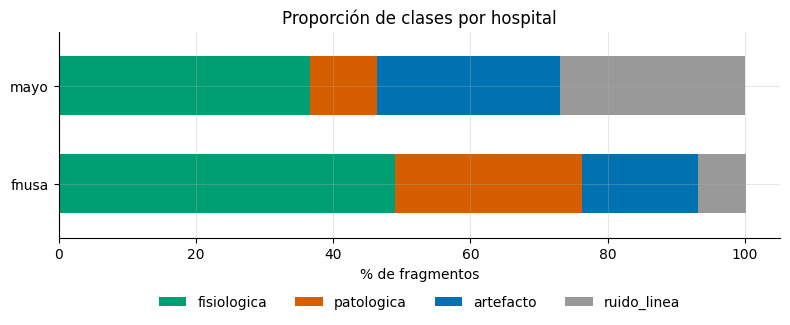

In [7]:
# Se trabaja desde aquí con los fragmentos únicos de pliegues.csv
pliegues = pd.read_csv(DATOS / "pliegues.csv")
datos = {h: crudo[h].merge(pliegues.loc[pliegues["hospital"] == h, ["segment_id", "pliegue"]],
                           on="segment_id", validate="one_to_one")
         for h in crudo}
for h in datos:
    print(f"{h}: {len(crudo[h]):,} -> {len(datos[h]):,} fragmentos únicos")

conteo = pd.DataFrame({h: datos[h]["clase"].value_counts() for h in datos}).loc[CLASES]
proporcion = (conteo / conteo.sum() * 100).round(1)
display_tabla = conteo.astype(str) + " (" + proporcion.astype(str) + " %)"
print(display_tabla.to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
proporcion.T.plot.barh(stacked=True, ax=ax, color=[COLOR_CLASE[c] for c in CLASES], width=0.6)
ax.set_xlabel("% de fragmentos")
ax.set_ylabel("")
ax.set_title("Proporción de clases por hospital")
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
plt.tight_layout()
plt.show()

**Lectura.** Las clases están desbalanceadas y la proporción cambia entre hospitales: la clase patológica es el 27 % en FNUSA y solo el 10 % en Mayo, y el ruido de línea pasa del 7 % al 27 %.

**Decisiones:**
- **Métrica principal: F1 de la clase patológica**, que no depende de cuántos fragmentos haya de las otras clases. La exactitud no sirve: un modelo que siempre dijera «fisiológica» tendría casi 50 % de exactitud en FNUSA y F1 patológica de 0. Como métrica secundaria, F1 macro (las cuatro clases con el mismo peso).
- **Pesos por clase** (`class_weight="balanced"`) en los modelos que lo admiten, en lugar de generar datos sintéticos.

### 2.2 Fragmentos por paciente: la clase está ligada al paciente

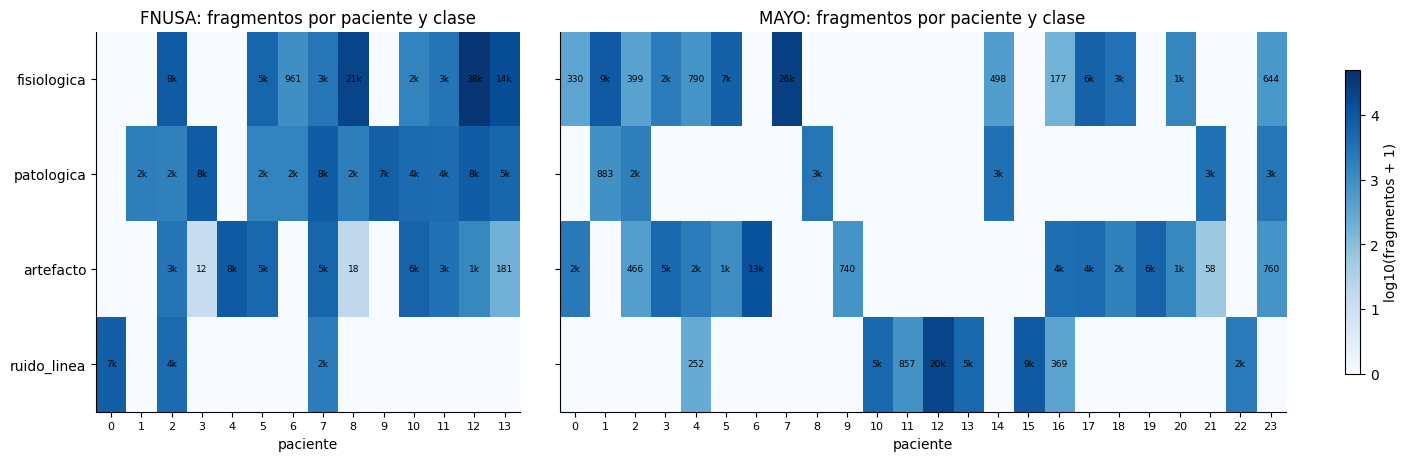

fnusa: 1,908–47,225 fragmentos por paciente; 4 pacientes con una sola clase; 12 de 14 pacientes tienen fragmentos patológicos
mayo: 740–25,948 fragmentos por paciente; 11 pacientes con una sola clase; 6 de 24 pacientes tienen fragmentos patológicos


In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [14, 24], "wspace": 0.05},
                         constrained_layout=True)
for ax, h in zip(ejes, ["fnusa", "mayo"]):
    tabla = pd.crosstab(datos[h]["clase"], datos[h]["patient_id"]).reindex(CLASES)
    im = ax.imshow(np.log10(tabla + 1), cmap="Blues", aspect="auto", vmin=0, vmax=4.7)
    ax.set_yticks(range(len(CLASES)), CLASES if h == "fnusa" else [])
    ax.set_xticks(range(tabla.shape[1]), tabla.columns, fontsize=8)
    ax.set_xlabel("paciente")
    ax.set_title(f"{h.upper()}: fragmentos por paciente y clase")
    ax.grid(False)
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            if tabla.iat[i, j] > 0:
                ax.text(j, i, f"{tabla.iat[i, j] / 1000:.0f}k" if tabla.iat[i, j] >= 1000 else tabla.iat[i, j],
                        ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ejes, shrink=0.8, label="log10(fragmentos + 1)")
plt.show()

for h in datos:
    por_paciente = datos[h].groupby("patient_id").size()
    clases_por_paciente = datos[h].groupby("patient_id")["clase"].nunique()
    con_pat = datos[h].loc[datos[h]["clase"] == "patologica", "patient_id"].nunique()
    print(f"{h}: {por_paciente.min():,}–{por_paciente.max():,} fragmentos por paciente; "
          f"{(clases_por_paciente == 1).sum()} pacientes con una sola clase; "
          f"{con_pat} de {len(por_paciente)} pacientes tienen fragmentos patológicos")

**Lectura.** Hay muchas mediciones por paciente (de cientos a decenas de miles) y la clase depende mucho del paciente: en Mayo varios pacientes aportan una sola clase y solo 6 de 24 tienen fragmentos patológicos.

**Decisiones:**
- **Partición por paciente** (`StratifiedGroupKFold`, 5 pliegues): todos los fragmentos de un paciente quedan en el mismo pliegue. Partir al azar pondría fragmentos casi iguales del mismo paciente en entrenamiento y en prueba.
- **P1 y P2 se responden con FNUSA**, donde 12 de 14 pacientes tienen patología. Mayo se usa como hospital externo en P3.

### 2.3 Cómo se ve cada clase

Un ejemplo por clase, tomado del subconjunto de señales submuestreadas a 1250 Hz que se preparó para la CNN.

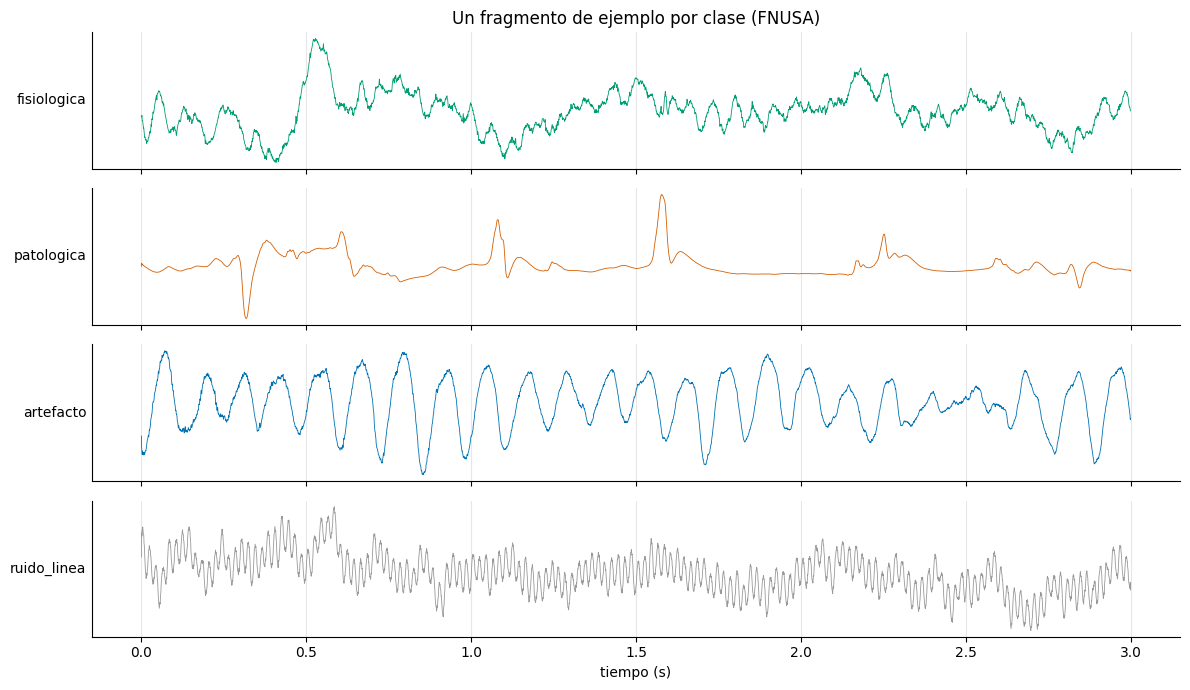

In [9]:
# El subconjunto (~300 MB) no está en el repositorio: lo genera scripts/preparar_subconjunto_cnn.py
RUTA_SUB = DATOS / "cnn_subconjunto_fnusa.npz"
subconjunto = np.load(RUTA_SUB) if RUTA_SUB.exists() else None
FS_SUB = 1250

if subconjunto is not None:
    t = np.arange(subconjunto["x"].shape[1]) / FS_SUB
    rng = np.random.default_rng(SEMILLA)
    fig, ejes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
    for ax, clase_orig, clase in zip(ejes, ["physiology", "pathology", "noise", "powerline_50hz"], CLASES):
        i = rng.choice(np.flatnonzero(subconjunto["y"] == clase_orig))
        ax.plot(t, subconjunto["x"][i].astype(float), color=COLOR_CLASE[clase], lw=0.6)
        ax.set_ylabel(clase, rotation=0, ha="right", va="center")
        ax.set_yticks([])
    ejes[-1].set_xlabel("tiempo (s)")
    ejes[0].set_title("Un fragmento de ejemplo por clase (FNUSA)")
    plt.tight_layout()
    plt.show()
else:
    print(f"No se encontró {RUTA_SUB}; ver el README para generarlo.")

### 2.4 Distribución de atributos por clase

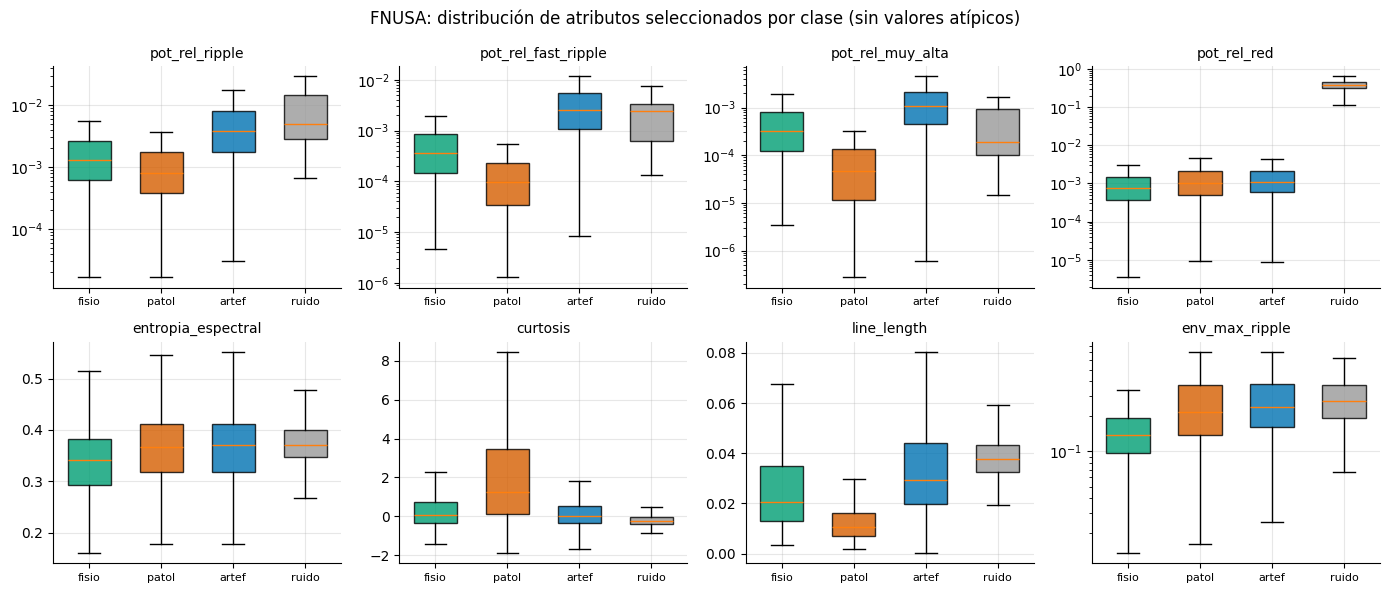

Atributos con asimetría > 2:
curtosis                 319.2
max_dif                  152.1
pot_rel_muy_alta          65.9
env_max_fast_ripple       22.7
planitud_espectral        17.5
pot_rel_ripple            13.1
pot_rel_fast_ripple       12.2
env_max_ripple             9.4
borde_espectral_95         7.7
frec_mediana               6.4
max_abs                    6.1
cociente_ripple_gamma      5.8
pico_a_pico                4.8
cociente_fr_ripple         4.0
frec_pico                  3.8
pot_rel_red                3.7
pot_rel_gamma              3.5
n_picos_3de                3.0
hjorth_complejidad         2.2
hjorth_movilidad           2.1
pot_rel_beta               2.0


In [10]:
CLAVE = ["pot_rel_ripple", "pot_rel_fast_ripple", "pot_rel_muy_alta", "pot_rel_red",
         "entropia_espectral", "curtosis", "line_length", "env_max_ripple"]
fnusa = datos["fnusa"]
fig, ejes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(ejes.ravel(), CLAVE):
    valores = [fnusa.loc[fnusa["clase"] == c, col] for c in CLASES]
    partes = ax.boxplot(valores, showfliers=False, patch_artist=True, widths=0.6)
    for caja, c in zip(partes["boxes"], CLASES):
        caja.set_facecolor(COLOR_CLASE[c])
        caja.set_alpha(0.8)
    ax.set_xticks(range(1, 5), [c[:5] for c in CLASES], fontsize=8)
    ax.set_title(col, fontsize=10)
    if fnusa[col].min() > 0 and fnusa[col].max() / fnusa[col].median() > 20:
        ax.set_yscale("log")
fig.suptitle("FNUSA: distribución de atributos seleccionados por clase (sin valores atípicos)")
plt.tight_layout()
plt.show()

# Asimetría de cada atributo: indica cuáles conviene pasar a escala logarítmica
asim = fnusa[ATRIBUTOS].skew().sort_values(ascending=False)
print("Atributos con asimetría > 2:")
print(asim[asim > 2].round(1).to_string())

**Lectura.** Varios atributos separan clases a simple vista:

- La potencia en la red identifica casi por completo el **ruido de línea**.
- La clase **patológica** tiene la mayor curtosis (espigas aisladas) y, en proporción, *menos* potencia en *ripple*, *fast ripple* y muy alta frecuencia: sus espigas grandes concentran la energía en frecuencias bajas, así que la potencia relativa en alta frecuencia baja aunque haya HFOs.
- Los **artefactos** tienen la mayor potencia relativa en *fast ripple* y en 500–1000 Hz, propia de la actividad muscular de banda ancha.
- La envolvente máxima en *ripple* es parecida en patológica y artefacto: esa superposición es la confusión que estudia P2.

**Decisión:** las potencias, cocientes, la planitud y las envolventes tienen colas muy largas (asimetría > 2), así que se pasan a **escala logarítmica**. Es una transformación fija por fragmento, sin parámetros aprendidos de los datos, y por eso no introduce fugas.

### 2.5 Redundancia entre atributos

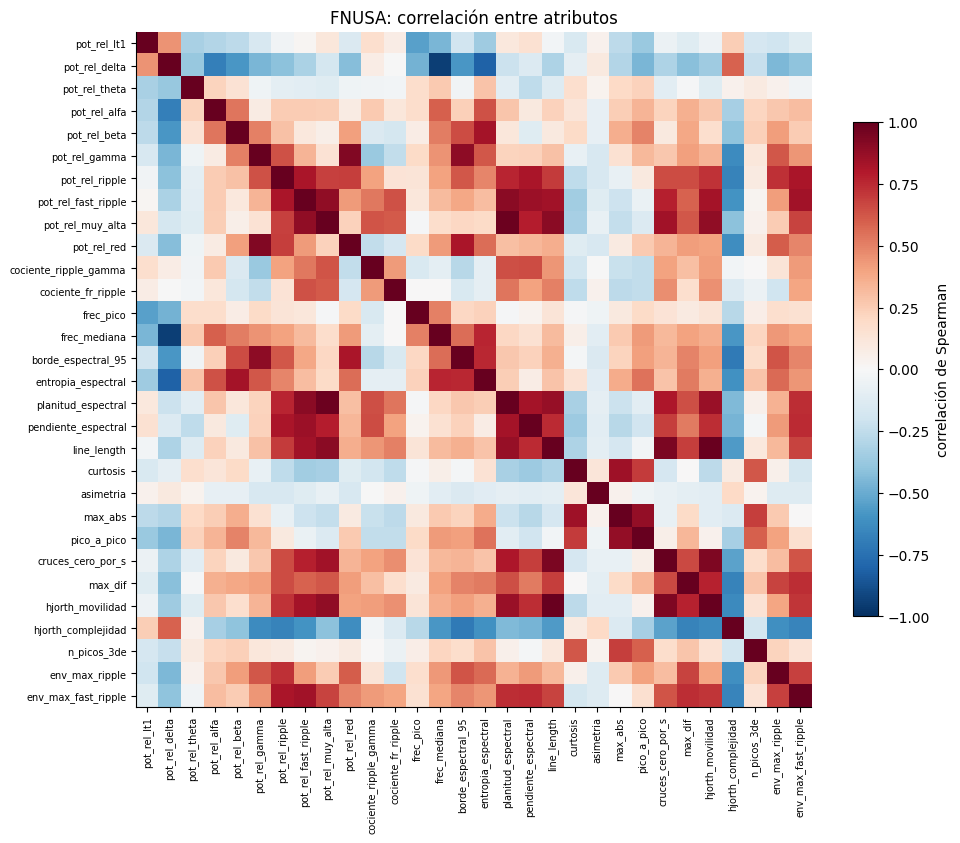

Pares con |r| > 0.95: 2
  pot_rel_muy_alta       ~ planitud_espectral     r = +0.979
  line_length            ~ hjorth_movilidad       r = +0.988


In [11]:
corr = fnusa[ATRIBUTOS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ATRIBUTOS)), ATRIBUTOS, rotation=90, fontsize=7)
ax.set_yticks(range(len(ATRIBUTOS)), ATRIBUTOS, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="correlación de Spearman")
ax.set_title("FNUSA: correlación entre atributos")
plt.tight_layout()
plt.show()

pares = [(a, b, corr.loc[a, b]) for i, a in enumerate(ATRIBUTOS) for b in ATRIBUTOS[i + 1:]
         if abs(corr.loc[a, b]) > 0.95]
print(f"Pares con |r| > 0.95: {len(pares)}")
for a, b, r in pares:
    print(f"  {a:22s} ~ {b:22s} r = {r:+.3f}")

**Lectura.** Hay grupos de atributos redundantes (por ejemplo, cruces por cero, frecuencia mediana y movilidad de Hjorth miden la rapidez de la señal).

**Decisión:** no se eliminan atributos antes de partir. Decidir qué quitar mirando todos los datos usaría información de los fragmentos de prueba. Los modelos de árboles toleran la redundancia, la regresión logística está regularizada y la selección de atributos se estudia dentro de los pliegues en P2.

### 2.6 Estructura en dos dimensiones: PCA, t-SNE y k-means

Se proyectan los atributos (en escala log y estandarizados) de una muestra de 6,000 fragmentos de FNUSA. La pregunta es si los grupos naturales de los datos siguen a la **clase** o al **paciente**.

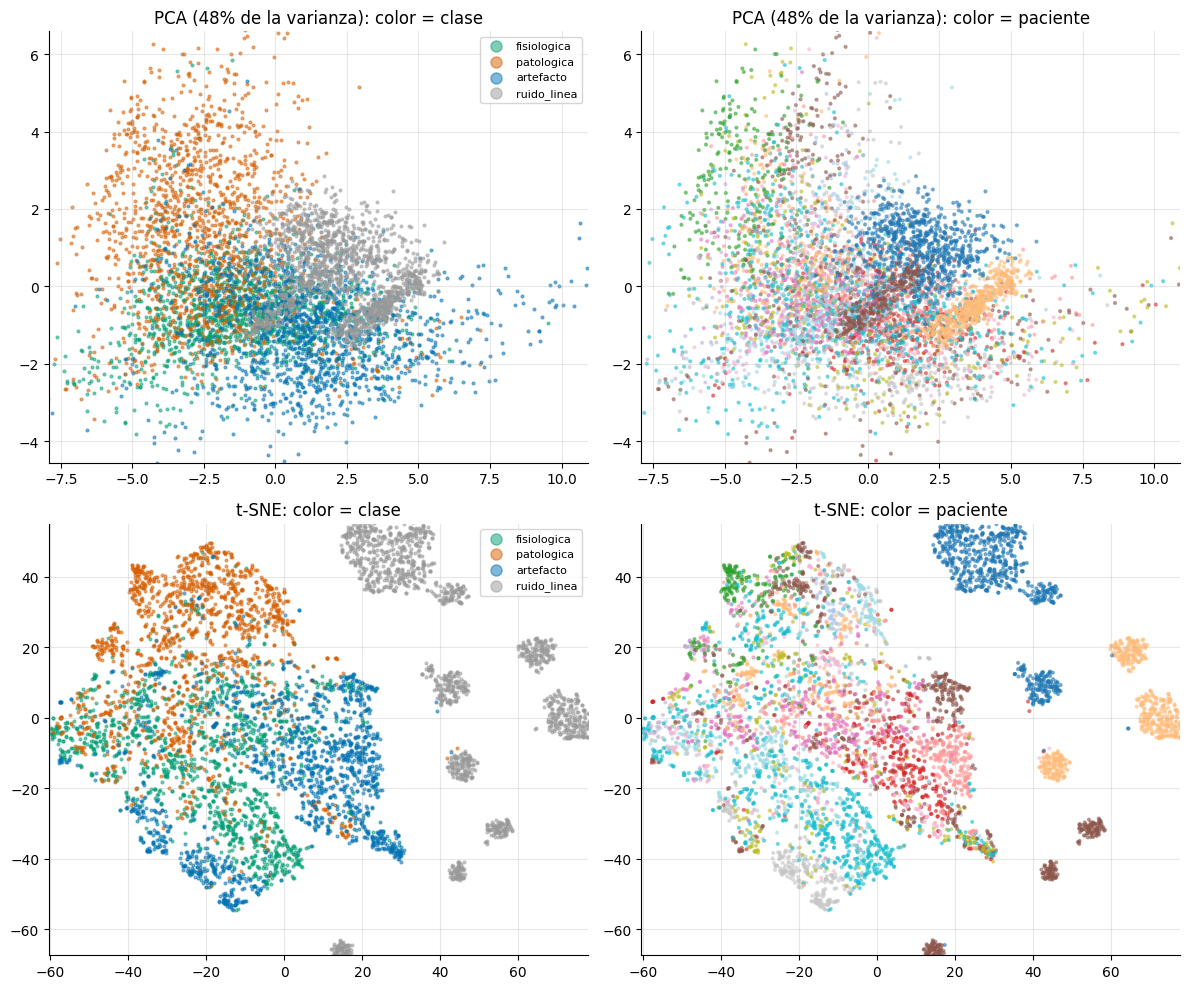

Concordancia de los grupos de k-means (0 = azar, 1 = idéntico):
  con clase     : ARI = 0.466, NMI = 0.551
  con patient_id: ARI = 0.126, NMI = 0.280


In [12]:
COLUMNAS_LOG = [c for c in ATRIBUTOS
                if c.startswith(("pot_rel_", "cociente_", "env_max_")) or c == "planitud_espectral"]


def transformar(df):
    """Transformación fija por fragmento: log10 de los atributos con cola larga."""
    X = df[ATRIBUTOS].astype(float).copy()
    X[COLUMNAS_LOG] = np.log10(X[COLUMNAS_LOG] + 1e-8)
    return X


muestra = fnusa.groupby("clase", group_keys=False).sample(n=1500, random_state=SEMILLA)
Z = StandardScaler().fit_transform(transformar(muestra))
pca = PCA(n_components=2, random_state=SEMILLA).fit(Z)
Z_pca = pca.transform(Z)
Z_tsne = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEMILLA).fit_transform(Z)

fig, ejes = plt.subplots(2, 2, figsize=(12, 10))
for fila, (Z2, nombre) in enumerate([(Z_pca, f"PCA ({pca.explained_variance_ratio_.sum():.0%} de la varianza)"),
                                      (Z_tsne, "t-SNE")]):
    ax = ejes[fila, 0]
    for c in CLASES:
        m = (muestra["clase"] == c).to_numpy()
        ax.scatter(Z2[m, 0], Z2[m, 1], s=4, alpha=0.5, color=COLOR_CLASE[c], label=c)
    ax.set_title(f"{nombre}: color = clase")
    ax.legend(markerscale=4, fontsize=8)
    ax = ejes[fila, 1]
    sc = ax.scatter(Z2[:, 0], Z2[:, 1], s=4, alpha=0.5, c=muestra["patient_id"], cmap="tab20")
    ax.set_title(f"{nombre}: color = paciente")
    # Límites robustos: unos pocos fragmentos extremos aplastarían la vista en PCA
    for a in ejes[fila]:
        a.set_xlim(*np.percentile(Z2[:, 0], [0.5, 99.5]) + np.array([-1, 1]))
        a.set_ylim(*np.percentile(Z2[:, 1], [0.5, 99.5]) + np.array([-1, 1]))
plt.tight_layout()
plt.show()

# k-means con k = 4: ¿sus grupos coinciden más con la clase o con el paciente?
grupos = KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit_predict(Z)
print("Concordancia de los grupos de k-means (0 = azar, 1 = idéntico):")
for ref in ["clase", "patient_id"]:
    print(f"  con {ref:10s}: ARI = {adjusted_rand_score(muestra[ref], grupos):.3f}, "
          f"NMI = {normalized_mutual_info_score(muestra[ref], grupos):.3f}")

**Lectura.** En t-SNE el ruido de línea forma grupos separados, y fisiológica, patológica y artefacto se separan en parte, con mucha superposición en las fronteras. Al colorear por paciente, varios grupos corresponden a **un solo paciente** (sobre todo en ruido de línea): cada paciente deja una huella propia en los atributos. k-means concuerda más con la clase que con el paciente, pero la concordancia con el paciente no es nula. PCA, que es lineal, separa mucho peor que t-SNE.

**Decisiones:** validar con **pacientes que el modelo no vio**, porque un modelo podría apoyarse en la huella del paciente; y comparar modelos lineales con no lineales, porque la estructura no es lineal.

## 3. Preprocesamiento y partición

Pasos, en orden:

1. **Duplicados:** eliminados antes de partir (`pliegues.csv` solo tiene fragmentos únicos).
2. **Transformación log10** de los atributos con cola larga: fija por fragmento, no aprende de los datos.
3. **Estandarización** (`StandardScaler`) **dentro de un `Pipeline`**: se ajusta solo con los datos de entrenamiento de cada pliegue, nunca con los de prueba. Se aplica a los modelos sensibles a la escala (regresión logística, kNN, SVM, MLP).
4. **Partición:** 5 pliegues de `StratifiedGroupKFold` agrupados por paciente y estratificados por clase, con semilla fija, guardados en `pliegues.csv` por `scripts/crear_pliegues.py`. Todos los modelos, incluida la CNN, usan **los mismos pliegues**.

Se verifica que ningún paciente aparezca en dos pliegues.

In [13]:
def preparar(df):
    """Devuelve X (atributos transformados), y (clase), grupos (paciente) y pliegue."""
    return (transformar(df).to_numpy(), df["clase"].to_numpy(),
            df["patient_id"].to_numpy(), df["pliegue"].to_numpy())


X_f, y_f, g_f, k_f = preparar(datos["fnusa"])
X_m, y_m, g_m, k_m = preparar(datos["mayo"])
print(f"FNUSA: X {X_f.shape}, Mayo: X {X_m.shape}; valores no finitos: {(~np.isfinite(X_f)).sum() + (~np.isfinite(X_m)).sum()}")

# Verificación de no fuga: ningún paciente en más de un pliegue
for h, g, k in [("fnusa", g_f, k_f), ("mayo", g_m, k_m)]:
    assert (pd.Series(k).groupby(g).nunique() == 1).all(), f"Paciente repartido en dos pliegues en {h}"

composicion = pd.crosstab(pd.Series(k_f, name="pliegue"), pd.Series(y_f, name="clase"))[CLASES]
composicion["pacientes"] = pd.Series(g_f).groupby(k_f).apply(lambda s: sorted(s.unique()))
print("FNUSA: composición de cada pliegue de prueba")
composicion

FNUSA: X (193044, 30), Mayo: X (155161, 30); valores no finitos: 0
FNUSA: composición de cada pliegue de prueba


clase,fisiologica,patologica,artefacto,ruido_linea,pacientes
pliegue,,,,,
0,40900,15448,6720,2042,"[7, 12]"
1,15680,9570,6057,0,"[10, 13]"
2,961,10211,8463,0,"[1, 4, 6, 9]"
3,5452,9601,5070,7130,"[0, 3, 5]"
4,31556,7621,6249,4313,"[2, 8, 11]"


Los cinco pliegues tienen fragmentos patológicos. Dos pliegues no tienen ruido de línea, porque esa clase viene de pocos pacientes; eso no afecta a la métrica principal (F1 patológica), pero sí al F1 macro secundario, así que también se reporta **sobre todas las predicciones fuera de pliegue juntas**, donde están las cuatro clases.

## 4. Modelado

### 4.1 Procedimiento común

Para que la comparación sea justa, todos los modelos se evalúan con la misma función: mismos atributos, mismos pliegues, mismas predicciones fuera de pliegue y misma métrica. Los hiperparámetros se fijan con valores razonables y no se ajustan mirando los pliegues de prueba.

In [14]:
def f1_patologica(y, pred):
    """F1 de la clase patológica (métrica principal): 2·VP / (2·VP + FP + FN)."""
    return f1_score(y, pred, labels=["patologica"], average=None, zero_division=0)[0]


def submuestra_estratificada(idx, y, n):
    """Toma n índices de idx conservando la proporción de clases (semilla fija)."""
    if not n or len(idx) <= n:
        return idx
    return (pd.Series(idx).groupby(y[idx], group_keys=False)
            .apply(lambda s: s.sample(frac=n / len(idx), random_state=SEMILLA))
            .to_numpy())


def ajustar(modelo, X, y, pesos=False):
    """Clona y entrena un modelo.

    Con pesos=True se balancean las clases para el último paso del Pipeline (el MLP):
    con pesos por muestra si la versión de scikit-learn los admite (>= 1.7) y, si no,
    sobremuestreando al azar las clases minoritarias del entrenamiento.
    """
    m = clone(modelo)
    if not pesos:
        return m.fit(X, y)
    if "sample_weight" in inspect.signature(m.steps[-1][1].fit).parameters:
        return m.fit(X, y, **{m.steps[-1][0] + "__sample_weight": compute_sample_weight("balanced", y)})
    rng_s = np.random.default_rng(SEMILLA)
    n_max = pd.Series(y).value_counts().max()
    idx = np.concatenate([rng_s.choice(np.flatnonzero(y == c), size=n_max, replace=True) for c in np.unique(y)])
    return m.fit(X[idx], y[idx])


def evaluar_cv(nombre, modelo, X, y, pliegue, n_entrenamiento=None, pesos=False):
    """Validación cruzada con pliegues fijos.

    Parámetros
    ----------
    modelo : estimador de scikit-learn (se clona en cada pliegue).
    n_entrenamiento : si se da, se entrena con una submuestra estratificada de ese tamaño
        (para kNN y SVM, cuyo costo crece mucho con el número de ejemplos). Se evalúa
        siempre con el pliegue de prueba completo.
    pesos : si es True, se pasan pesos por clase balanceados en fit (para el MLP, que no
        tiene `class_weight`).

    Devuelve un diccionario con el F1 de la clase patológica (métrica principal) y el F1
    macro (secundaria), por pliegue y global, las predicciones fuera de pliegue y el tiempo.
    """
    pred = np.empty(len(y), dtype=object)
    f1_pliegue, f1m_pliegue = [], []
    t0 = time.time()
    for k in np.unique(pliegue):
        entr, prueba = pliegue != k, pliegue == k
        idx = submuestra_estratificada(np.flatnonzero(entr), y, n_entrenamiento)
        m = ajustar(modelo, X[idx], y[idx], pesos)
        pred[prueba] = m.predict(X[prueba])
        f1_pliegue.append(f1_patologica(y[prueba], pred[prueba]))
        f1m_pliegue.append(f1_score(y[prueba], pred[prueba], average="macro"))
    res = {"modelo": nombre, "pred": pred, "segundos": time.time() - t0,
           "f1_pliegues": np.array(f1_pliegue), "f1_global": f1_patologica(y, pred),
           "f1m_pliegues": np.array(f1m_pliegue), "f1m_global": f1_score(y, pred, average="macro")}
    print(f"{nombre:30s} F1 patológica = {res['f1_pliegues'].mean():.3f} ± {res['f1_pliegues'].std():.3f} "
          f"(global {res['f1_global']:.3f}) | F1 macro = {res['f1m_pliegues'].mean():.3f}  [{res['segundos']:.0f} s]")
    return res

### 4.2 Líneas base

- **Clase mayoritaria:** siempre predice la clase más frecuente del entrenamiento. Es el piso mínimo.
- **Aleatoria estratificada:** predice al azar respetando las proporciones de clase.
- **Regla de umbrales:** un árbol de profundidad 2 con solo tres atributos de interpretación clínica directa (potencia relativa en *ripple*, en *fast ripple* y en la red eléctrica). Imita un detector simple de HFOs y de ruido de línea; si los modelos con 30 atributos no la superan, no vale la pena la complejidad.

In [15]:
idx_regla = [ATRIBUTOS.index(c) for c in ["pot_rel_ripple", "pot_rel_fast_ripple", "pot_rel_red"]]


class ReglaUmbrales(DecisionTreeClassifier):
    """Árbol de profundidad 2 restringido a tres atributos clínicos (línea base)."""

    def fit(self, X, y, sample_weight=None):
        return super().fit(X[:, idx_regla], y, sample_weight=sample_weight)

    def predict(self, X):
        return super().predict(X[:, idx_regla])


resultados = {}
for nombre, modelo in [
    ("Base: clase mayoritaria", DummyClassifier(strategy="most_frequent")),
    ("Base: aleatoria estratificada", DummyClassifier(strategy="stratified", random_state=SEMILLA)),
    ("Base: regla de umbrales", ReglaUmbrales(max_depth=2, class_weight="balanced", random_state=SEMILLA)),
]:
    resultados[nombre] = evaluar_cv(nombre, modelo, X_f, y_f, k_f)

Base: clase mayoritaria        F1 patológica = 0.000 ± 0.000 (global 0.000) | F1 macro = 0.145  [2 s]
Base: aleatoria estratificada  F1 patológica = 0.277 ± 0.041 (global 0.270) | F1 macro = 0.216  [2 s]
Base: regla de umbrales        F1 patológica = 0.596 ± 0.194 (global 0.547) | F1 macro = 0.458  [4 s]


### 4.3 Modelos del curso y red neuronal (MLP)

| Modelo | Por qué se incluye | Configuración |
|---|---|---|
| Regresión logística | Lineal e interpretable: indica si el problema es casi lineal | `C=1`, pesos por clase, estandarizada |
| Árbol de decisión | Umbrales parecidos al razonamiento de un experto | profundidad máx. 10, pesos por clase |
| Naive Bayes gaussiano | Muy rápido; prueba si los atributos sirven por separado | sin pesos (no los admite) |
| kNN | Clasifica por parecido entre fragmentos | k = 15, estandarizado, entrena con 20 mil fragmentos |
| SVM (kernel RBF) | Fronteras no lineales | pesos por clase, estandarizada, entrena con 10 mil fragmentos |
| Random forest | Reduce la varianza del árbol (bagging) | 150 árboles, hojas ≥ 5, pesos por subconjunto |
| Gradient boosting | Suele ser el mejor en datos tabulares | `HistGradientBoosting`, 300 rondas, tasa 0.1, pesos por clase |
| **MLP (deep learning, opción A)** | Red neuronal sobre los mismos atributos | capas de 64 y 32, 40 épocas, pesos por clase |

kNN y SVM se entrenan con una submuestra estratificada porque su costo crece con el cuadrado del número de ejemplos; se evalúan con el pliegue de prueba completo, igual que los demás. En gradient boosting y en el MLP **no se usa parada temprana interna**: apartaría un 10 % al azar del entrenamiento, con fragmentos del mismo paciente de ambos lados, y daría una validación optimista (sesión 18). Se fija el número de rondas y de épocas.

In [16]:
MODELOS = {
    "Regresión logística": make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=SEMILLA),
    "Naive Bayes": GaussianNB(),
    "kNN (k = 15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=1.0, class_weight="balanced", random_state=SEMILLA)),
    "Random forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=SEMILLA),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, class_weight="balanced",
                                                        early_stopping=False, random_state=SEMILLA),
    "MLP (red neuronal)": make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), batch_size=512, max_iter=40,
                                        early_stopping=False, random_state=SEMILLA)),
}
OPCIONES = {"kNN (k = 15)": {"n_entrenamiento": 20_000}, "SVM (RBF)": {"n_entrenamiento": 10_000},
            "MLP (red neuronal)": {"pesos": True}}

for nombre, modelo in MODELOS.items():
    resultados[nombre] = evaluar_cv(nombre, modelo, X_f, y_f, k_f, **OPCIONES.get(nombre, {}))

Regresión logística            F1 patológica = 0.688 ± 0.146 (global 0.677) | F1 macro = 0.578  [99 s]
Árbol de decisión              F1 patológica = 0.643 ± 0.144 (global 0.628) | F1 macro = 0.485  [45 s]
Naive Bayes                    F1 patológica = 0.654 ± 0.118 (global 0.650) | F1 macro = 0.580  [2 s]
kNN (k = 15)                   F1 patológica = 0.663 ± 0.147 (global 0.655) | F1 macro = 0.575  [29 s]
SVM (RBF)                      F1 patológica = 0.723 ± 0.171 (global 0.695) | F1 macro = 0.617  [74 s]
Random forest                  F1 patológica = 0.722 ± 0.174 (global 0.696) | F1 macro = 0.570  [851 s]
Gradient boosting              F1 patológica = 0.644 ± 0.141 (global 0.641) | F1 macro = 0.542  [186 s]
MLP (red neuronal)             F1 patológica = 0.691 ± 0.176 (global 0.664) | F1 macro = 0.561  [377 s]


## 5. Evaluación

### 5.1 Comparación entre modelos y variabilidad entre pliegues

In [17]:
tabla = pd.DataFrame({
    "F1 patológica (media)": {n: r["f1_pliegues"].mean() for n, r in resultados.items()},
    "desv. est. entre pliegues": {n: r["f1_pliegues"].std() for n, r in resultados.items()},
    "F1 patológica global": {n: r["f1_global"] for n, r in resultados.items()},
    "precisión patológica": {n: precision_score(y_f, r["pred"], labels=["patologica"], average=None)[0]
                             for n, r in resultados.items()},
    "sensibilidad patológica": {n: recall_score(y_f, r["pred"], labels=["patologica"], average=None)[0]
                                for n, r in resultados.items()},
    "F1 macro (media, secundaria)": {n: r["f1m_pliegues"].mean() for n, r in resultados.items()},
    "segundos": {n: r["segundos"] for n, r in resultados.items()},
}).sort_values("F1 patológica (media)", ascending=False).round(3)
tabla.to_csv(RESULTADOS / "comparacion_modelos_fnusa.csv")
tabla

,F1 patológica (media),desv. est. entre pliegues,F1 patológica global,precisión patológica,sensibilidad patológica,"F1 macro (media, secundaria)",segundos
SVM (RBF),0.723,0.171,0.695,0.626,0.783,0.617,73.643
Random forest,0.722,0.174,0.696,0.628,0.782,0.570,851.016
MLP (red neuronal),0.691,0.176,0.664,0.576,0.785,0.561,376.752
Regresión logística,0.688,0.146,0.677,0.621,0.744,0.578,99.135
kNN (k = 15),0.663,0.147,0.655,0.649,0.662,0.575,29.214
Naive Bayes,0.654,0.118,0.650,0.647,0.653,0.580,2.423
Gradient boosting,0.644,0.141,0.641,0.562,0.745,0.542,186.126
Árbol de decisión,0.643,0.144,0.628,0.557,0.719,0.485,44.697
Base: regla de umbrales,0.596,0.194,0.547,0.396,0.884,0.458,3.571
Base: aleatoria estratificada,0.277,0.041,0.270,0.264,0.276,0.216,2.366


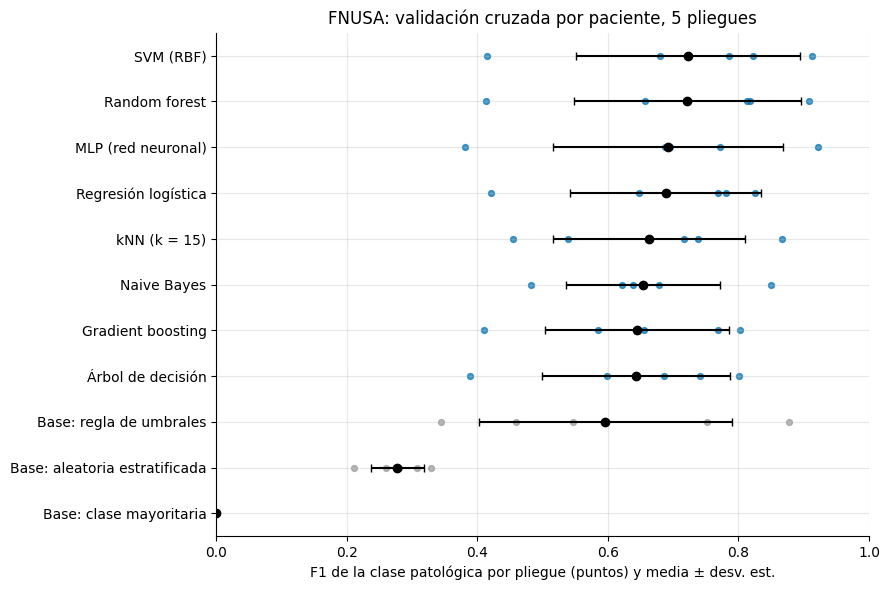

In [18]:
orden = tabla.index[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
for i, n in enumerate(orden):
    f1s = resultados[n]["f1_pliegues"]
    es_base = n.startswith("Base")
    ax.scatter(f1s, np.full(len(f1s), i), color="#999999" if es_base else "#0072B2", s=18, alpha=0.7)
    ax.errorbar(f1s.mean(), i, xerr=f1s.std(), fmt="o", color="black", capsize=3, ms=6)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlabel("F1 de la clase patológica por pliegue (puntos) y media ± desv. est.")
ax.set_title("FNUSA: validación cruzada por paciente, 5 pliegues")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

### 5.2 Intervalos de confianza por *bootstrap* de pacientes

Con solo 14 pacientes, la incertidumbre importante es *qué pacientes* tocaron. Se remuestrean pacientes con reemplazo (1,000 veces) sobre las predicciones fuera de pliegue y se recalcula el F1 de la clase patológica. También se calcula el intervalo de la **diferencia** entre el mejor modelo y la regla de umbrales: si no incluye el 0, la mejora no se explica por el azar de los pacientes.

In [19]:
def matrices_por_paciente(y, pred, grupos):
    """Matriz de confusión de cada paciente (para remuestrear pacientes rápidamente)."""
    return {p: confusion_matrix(y[grupos == p], pred[grupos == p], labels=CLASES) for p in np.unique(grupos)}


I_PAT = CLASES.index("patologica")


def f1_patologica_de_matriz(cm):
    """F1 de la clase patológica a partir de una matriz de confusión: 2·VP / (reales + predichos)."""
    vp = cm[I_PAT, I_PAT]
    denominador = cm[I_PAT, :].sum() + cm[:, I_PAT].sum()
    return 2 * vp / denominador if denominador else 0.0


def bootstrap_pacientes(preds, y, grupos, n=1000):
    """Distribución bootstrap (remuestreo de pacientes) del F1 patológica de cada modelo dado."""
    mats = {nom: matrices_por_paciente(y, p, grupos) for nom, p in preds.items()}
    pacientes = np.unique(grupos)
    rng_b = np.random.default_rng(SEMILLA)
    salida = {nom: [] for nom in preds}
    for _ in range(n):
        elegidos = rng_b.choice(pacientes, size=len(pacientes), replace=True)
        for nom in preds:
            salida[nom].append(f1_patologica_de_matriz(sum(mats[nom][p] for p in elegidos)))
    return {nom: np.array(v) for nom, v in salida.items()}


MEJOR = tabla.drop([n for n in tabla.index if n.startswith("Base")]).index[0]
SEGUNDO = tabla.drop([n for n in tabla.index if n.startswith("Base")]).index[1]
comparar = [MEJOR, SEGUNDO, "MLP (red neuronal)", "Base: regla de umbrales", "Base: clase mayoritaria"]
comparar = list(dict.fromkeys(comparar))
boot = bootstrap_pacientes({n: resultados[n]["pred"] for n in comparar}, y_f, g_f)

filas = []
for n in comparar:
    filas.append([n, resultados[n]["f1_global"], *np.percentile(boot[n], [2.5, 97.5])])
for a, b in [(MEJOR, "Base: regla de umbrales"), (MEJOR, SEGUNDO)]:
    d = boot[a] - boot[b]
    filas.append([f"Diferencia: {a} − {b}", resultados[a]["f1_global"] - resultados[b]["f1_global"],
                  *np.percentile(d, [2.5, 97.5])])
ic = pd.DataFrame(filas, columns=["", "F1 patológica global", "IC 95 % inf.", "IC 95 % sup."]).set_index("").round(3)
ic

,F1 patológica global,IC 95 % inf.,IC 95 % sup.
,,,
SVM (RBF),0.695,0.528,0.835
Random forest,0.696,0.521,0.839
MLP (red neuronal),0.664,0.505,0.806
Base: regla de umbrales,0.547,0.402,0.737
Base: clase mayoritaria,0.000,0.000,0.000
Diferencia: SVM (RBF) − Base: regla de umbrales,0.148,0.009,0.269
Diferencia: SVM (RBF) − Random forest,-0.001,-0.017,0.017


### 5.3 Análisis de errores del mejor modelo

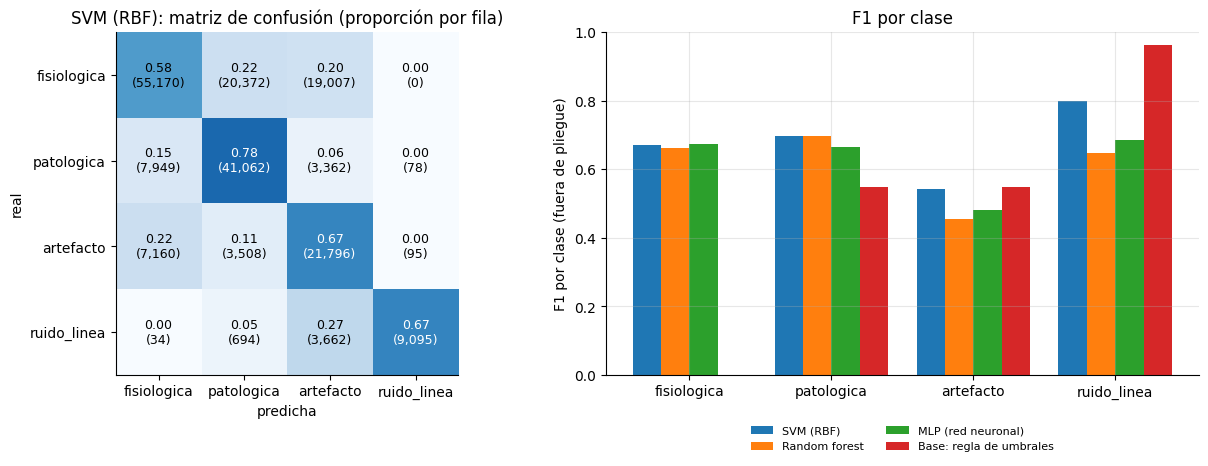

In [20]:
pred_mejor = resultados[MEJOR]["pred"]
cm = confusion_matrix(y_f, pred_mejor, labels=CLASES)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = ejes[0]
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]:,})", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.6 else "black", fontsize=9)
ax.set_xticks(range(4), CLASES)
ax.set_yticks(range(4), CLASES)
ax.set_xlabel("predicha")
ax.set_ylabel("real")
ax.grid(False)
ax.set_title(f"{MEJOR}: matriz de confusión (proporción por fila)")

# F1 por clase de los mejores modelos frente a la línea base
ax = ejes[1]
modelos_f1 = [MEJOR, SEGUNDO, "MLP (red neuronal)", "Base: regla de umbrales"]
modelos_f1 = list(dict.fromkeys(modelos_f1))
ancho = 0.8 / len(modelos_f1)
for i, n in enumerate(modelos_f1):
    f1c = f1_score(y_f, resultados[n]["pred"], labels=CLASES, average=None)
    ax.bar(np.arange(4) + i * ancho, f1c, width=ancho, label=n)
ax.set_xticks(np.arange(4) + ancho * (len(modelos_f1) - 1) / 2, CLASES)
ax.set_ylabel("F1 por clase (fuera de pliegue)")
ax.set_ylim(0, 1)
ax.legend(fontsize=8, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
ax.set_title("F1 por clase")
plt.tight_layout()
plt.show()

In [21]:
# Desempeño por paciente: ¿el error se concentra en algunos pacientes?
por_paciente = (pd.DataFrame({"paciente": g_f, "real": y_f, "pred": pred_mejor})
                .groupby("paciente")
                .apply(lambda d: pd.Series({
                    "fragmentos": len(d),
                    "clases": d["real"].nunique(),
                    "exactitud": (d["real"] == d["pred"]).mean(),
                    "recall patológica": ((d["real"] == "patologica") & (d["pred"] == "patologica")).sum()
                    / max((d["real"] == "patologica").sum(), 1) if (d["real"] == "patologica").any() else np.nan,
                }), include_groups=False)
                .round(3))
por_paciente

,fragmentos,clases,exactitud,recall patológica
paciente,,,,
0,7130.0,1.0,0.406,NaN
1,1908.0,1.0,0.930,0.930
2,16669.0,4.0,0.432,0.980
3,8086.0,2.0,0.939,0.939
4,8463.0,1.0,0.687,NaN
5,12037.0,3.0,0.618,0.773
6,2515.0,2.0,0.858,0.847
7,17885.0,4.0,0.810,0.740
8,22772.0,3.0,0.399,0.936


Recall de la clase patológica según si el electrodo está en la zona de inicio (soz):
     fragmentos  recall
soz                    
0         13892   0.750
1         35318   0.786
2          3241   0.886


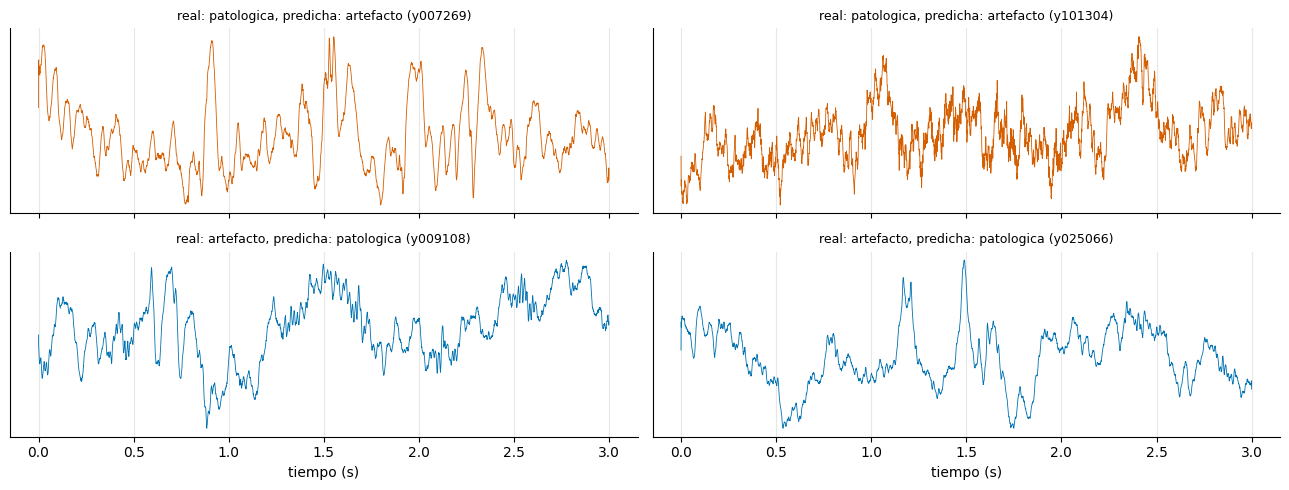

In [22]:
# ¿Los errores patológica <-> artefacto se relacionan con la zona de inicio de crisis (soz)?
fn = datos["fnusa"].assign(pred=pred_mejor)
pat = fn[fn["clase"] == "patologica"]
print("Recall de la clase patológica según si el electrodo está en la zona de inicio (soz):")
print(pat.groupby("soz").agg(fragmentos=("pred", "size"),
                             recall=("pred", lambda p: round((p == "patologica").mean(), 3))).to_string())

# Ejemplos de errores en el subconjunto de señales disponibles: patológica predicha como artefacto y al revés
if subconjunto is not None:
    sub_ids = pd.Series(np.arange(len(subconjunto["segment_id"])), index=subconjunto["segment_id"])
    fig, ejes = plt.subplots(2, 2, figsize=(13, 5), sharex=True)
    for fila, (real, predicha) in enumerate([("patologica", "artefacto"), ("artefacto", "patologica")]):
        casos = fn[(fn["clase"] == real) & (fn["pred"] == predicha) & fn["segment_id"].isin(sub_ids.index)]
        for col in range(2):
            ax = ejes[fila, col]
            if len(casos) > col:
                sid = casos["segment_id"].iloc[col * max(len(casos) // 2, 1)]
                ax.plot(t, subconjunto["x"][sub_ids[sid]].astype(float), color=COLOR_CLASE[real], lw=0.6)
                ax.set_title(f"real: {real}, predicha: {predicha} ({sid})", fontsize=9)
            ax.set_yticks([])
    ejes[-1, 0].set_xlabel("tiempo (s)")
    ejes[-1, 1].set_xlabel("tiempo (s)")
    plt.tight_layout()
    plt.show()

**Lectura del análisis de errores.**

- **Patológica** es la clase mejor detectada: el SVM recupera el 78 % de sus fragmentos, y la confunde sobre todo con fisiológica (15 %) y poco con artefacto (6 %).
- **Fisiológica** es la que más se confunde: el 22 % se predice como patológica y el 20 % como artefacto. Buena parte de los falsos positivos de patológica viene de aquí.
- **Ruido de línea**: cuando el modelo lo predice casi siempre acierta, pero el 27 % de esos fragmentos se predice como artefacto. Esos errores vienen sobre todo del paciente 0, que solo aporta ruido de línea y tiene una exactitud de 0.41: su ruido es distinto del de los pacientes de entrenamiento.
- **Por paciente**, la exactitud va de 0.35 a 0.94; esa variación explica la desviación estándar entre pliegues (0.17 en la F1 patológica).
- **Zona de inicio de crisis:** la clase patológica se detecta mejor en electrodos de la zona de inicio (`soz` = 1 o 2) que fuera de ella (`soz` = 0), lo que es coherente con que allí la actividad epileptiforme sea más marcada.
- En los ejemplos mal clasificados, los fragmentos patológicos predichos como artefacto tienen mucha actividad rápida e irregular, y los artefactos predichos como patológicos tienen deflexiones aisladas parecidas a espigas.

### 5.4 Intentos de mejora

Se probaron tres ideas para mejorar la F1 patológica, todas **con los mismos pliegues por paciente** y eligiendo cualquier parámetro **solo con el entrenamiento** de cada pliegue (validación interna por paciente), para no usar información de prueba:

1. **Normalización por paciente.** El EDA mostró que cada paciente deja una huella en los atributos. Se estandarizó cada atributo con la media y la desviación de los fragmentos del mismo paciente (sin usar etiquetas), sola o junto con los atributos originales.
2. **Umbral de decisión.** El SVM marca de más la clase patológica (precisión 0.63, sensibilidad 0.78). Se eligió, con 3 pliegues internos por paciente, el umbral sobre el margen de la clase patológica que maximiza su F1.
3. **Hiperparámetros con validación anidada** para gradient boosting (profundidad, hojas mínimas, rondas) y SVM (C, gamma), más un SVM entrenado con 30 mil fragmentos en lugar de 10 mil.

Son costosos (unas 2 horas), así que se ejecutaron aparte con `scripts/experimentos_mejora.py`, que usa la misma transformación y los mismos modelos que este notebook. Aquí se cargan y se analizan sus resultados.

In [23]:
RUTA_MEJ = RESULTADOS / "mejoras_pliegues.csv"
if RUTA_MEJ.exists():
    mej = pd.read_csv(RUTA_MEJ)
    pred_mej = (pd.read_csv(RESULTADOS / "mejoras_predicciones.csv.gz")
                .set_index("segment_id").loc[datos["fnusa"]["segment_id"]])
    resumen = (mej.groupby(["experimento", "modelo", "variante"], sort=False)
               .agg(**{"F1 patológica (media)": ("f1_patologica", "mean"),
                       "desv. est.": ("f1_patologica", lambda v: np.std(v)),
                       "F1 macro (media)": ("f1_macro", "mean")}))
    resumen["F1 patológica global"] = [f1_patologica(y_f, pred_mej[" | ".join(i)].to_numpy()) for i in resumen.index]
    print("Referencia actual (sección 5.1): SVM (RBF), F1 patológica = "
          f"{resultados['SVM (RBF)']['f1_pliegues'].mean():.3f} ± {resultados['SVM (RBF)']['f1_pliegues'].std():.3f}")
    display_mej = resumen.round(3)
else:
    display_mej = None
    print("No se encontró resultados/mejoras_pliegues.csv: ejecutar scripts/experimentos_mejora.py (ver README).")
display_mej

Referencia actual (sección 5.1): SVM (RBF), F1 patológica = 0.723 ± 0.171


F1 patológica (media)  \
experimento                   modelo              variante                                                       
1. normalización por paciente Regresión logística original                                               0.688   
                                                  normalizado por paciente                               0.564   
                                                  original + normalizado                                 0.594   
                              SVM (RBF)           original                                               0.723   
                                                  normalizado por paciente                               0.608   
                                                  original + normalizado                                 0.677   
                              Gradient boosting   original                                               0.557   
                                                  normalizado por paciente                               0.516   
                                                  original + normalizado                                 0.659   
                              Random forest       original                                               0.722   
                                                  normalizado por paciente                               0.562   
                                                  original + normalizado                                 0.677   
2. umbral                     Regresión logística clase más probable                                     0.688   
                                                  umbral elegido por validación interna                  0.672   
                              SVM (RBF)           clase más probable                                     0.723   
                                                  umbral elegido por validación interna                  0.687   
                              Random forest       clase más probable                                     0.722   
                                                  umbral elegido por validación interna                  0.697   
3. hiperparámetros            Gradient boosting   valores por omisión                                    0.557   
                                                  validación anidada                                     0.675   
                              SVM (RBF)           valores por omisión                                    0.723   
                                                  validación anidada                                     0.738   
                                                  entrenado con 30 mil fragmentos                        0.717   

                                                                                         desv. est.  \
experimento                   modelo              variante                                            
1. normalización por paciente Regresión logística original                                    0.146   
                                                  normalizado por paciente                    0.162   
                                                  original + normalizado                      0.172   
                              SVM (RBF)           original                                    0.171   
                                                  normalizado por paciente                    0.131   
                                                  original + normalizado                      0.166   
                              Gradient boosting   original                                    0.183   
                                                  normalizado por paciente                    0.125   
                                                  original + normalizado                      0.190   
                              Random forest       original                                    0.175   
  

2. umbral · Regresión logística
    pliegue 0: +0.371
    pliegue 1: +0.156
    pliegue 2: +0.593
    pliegue 3: +0.233
    pliegue 4: +0.422
2. umbral · SVM (RBF)
    pliegue 0: +1.005
    pliegue 1: +1.023
    pliegue 2: +1.027
    pliegue 3: +0.000
    pliegue 4: +0.994
2. umbral · Random forest
    pliegue 0: +0.359
    pliegue 1: +0.351
    pliegue 2: +0.151
    pliegue 3: +0.083
    pliegue 4: +0.346
3. hiperparámetros · Gradient boosting
    pliegue 0: {'max_depth': 6, 'min_samples_leaf': 1000, 'max_iter': 100}
    pliegue 1: {'max_depth': 3, 'min_samples_leaf': 1000, 'max_iter': 100}
    pliegue 2: {'max_depth': 3, 'min_samples_leaf': 100, 'max_iter': 100}
    pliegue 3: {'max_depth': 6, 'min_samples_leaf': 100, 'max_iter': 300}
    pliegue 4: {'max_depth': 3, 'min_samples_leaf': 100, 'max_iter': 300}
3. hiperparámetros · SVM (RBF)
    pliegue 0: {'C': 0.3, 'gamma': 0.01}
    pliegue 1: {'C': 0.3, 'gamma': 0.01}
    pliegue 2: {'C': 1.0, 'gamma': 0.01}
    pliegue 3: {'C': 1.0,

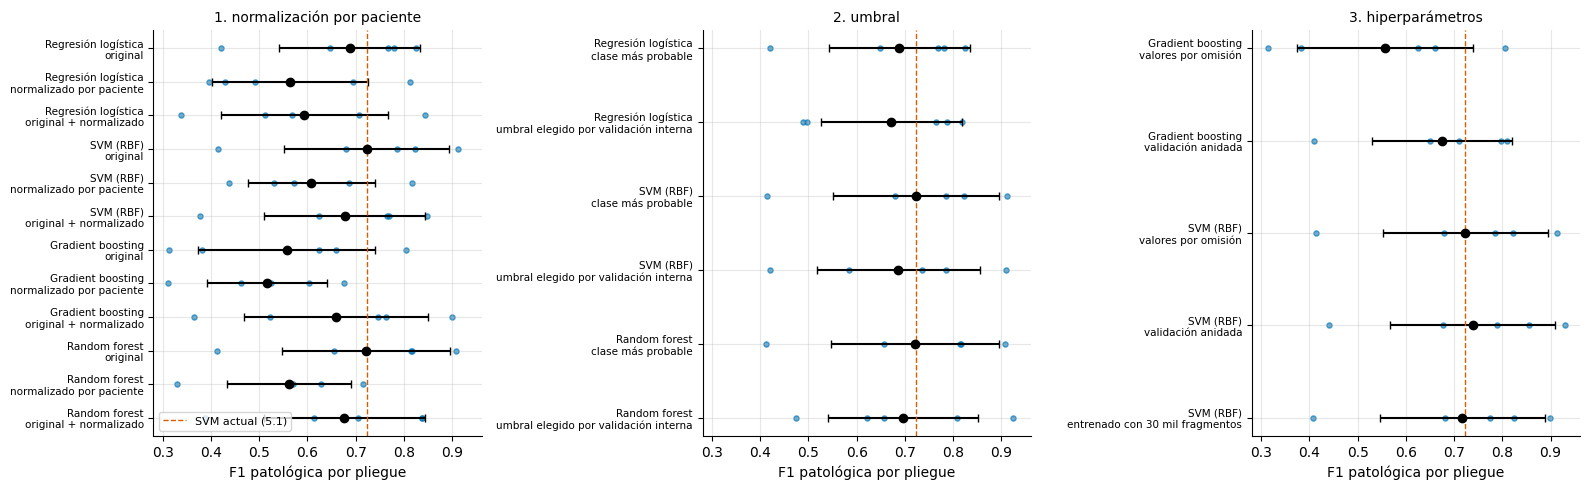


Mejor variante: 3. hiperparámetros | SVM (RBF) | validación anidada
Diferencia de F1 patológica global frente al SVM actual: +0.019 (IC 95 %: +0.003 a +0.034)


In [24]:
if display_mej is not None:
    # Valores elegidos dentro de cada pliegue (umbral e hiperparámetros)
    detalle = pd.read_csv(RESULTADOS / "mejoras_detalle.csv")
    for (e, m), d in detalle.groupby(["experimento", "modelo"], sort=False):
        print(f"{e} · {m}")
        for _, fila in d.iterrows():
            print(f"    pliegue {fila['pliegue']}: {fila['elegido']}")

    # Figura: F1 patológica por pliegue de cada variante, por experimento
    exps = list(dict.fromkeys(mej["experimento"]))
    fig, ejes = plt.subplots(1, len(exps), figsize=(16, 5), sharex=True)
    ref = resultados["SVM (RBF)"]["f1_pliegues"].mean()
    for ax, e in zip(np.atleast_1d(ejes), exps):
        sub = resumen.loc[e]
        etiquetas = [f"{m}\n{v}" for m, v in sub.index]
        for i, (m, v) in enumerate(sub.index):
            f = mej.query("experimento == @e and modelo == @m and variante == @v")["f1_patologica"]
            ax.scatter(f, np.full(len(f), i), s=14, alpha=0.6, color="#0072B2")
            ax.errorbar(f.mean(), i, xerr=np.std(f), fmt="o", color="black", capsize=3)
        ax.axvline(ref, color="#D55E00", ls="--", lw=1, label="SVM actual (5.1)")
        ax.set_yticks(range(len(sub)), etiquetas, fontsize=7.5)
        ax.invert_yaxis()
        ax.set_title(e, fontsize=10)
        ax.set_xlabel("F1 patológica por pliegue")
    np.atleast_1d(ejes)[0].legend(fontsize=8, loc="lower left")
    plt.tight_layout()
    plt.show()

    # Mejor variante de todos los experimentos frente al SVM actual: IC por bootstrap de pacientes
    candidatas = resumen.drop(index=[i for i in resumen.index if i[2] in
                                     ("original", "clase más probable", "valores por omisión")])
    mejor_var = candidatas["F1 patológica (media)"].idxmax()
    pred_var = pred_mej[" | ".join(mejor_var)].to_numpy()
    boot_m = bootstrap_pacientes({"svm": resultados["SVM (RBF)"]["pred"], "variante": pred_var}, y_f, g_f)
    d = boot_m["variante"] - boot_m["svm"]
    print(f"\nMejor variante: {' | '.join(mejor_var)}")
    print(f"Diferencia de F1 patológica global frente al SVM actual: "
          f"{f1_patologica(y_f, pred_var) - resultados['SVM (RBF)']['f1_global']:+.3f} "
          f"(IC 95 %: {np.percentile(d, 2.5):+.3f} a {np.percentile(d, 97.5):+.3f})")

**Lectura de los intentos de mejora.**

- **La normalización por paciente empeora a todos los modelos** (por ejemplo, el SVM baja de 0.72 a 0.61). La razón está en cómo se armó el dataset: los fragmentos de cada paciente se seleccionaron por clase, y varios pacientes aportan una sola clase. Restar la media del paciente borra justo esa información (un paciente que solo tiene ruido de línea queda "centrado" en cero). Agregar los atributos normalizados a los originales tampoco ayuda, salvo al gradient boosting, que de todos modos queda por debajo del SVM. **Se descarta.**
- **Ajustar el umbral no mejora** (el SVM baja de 0.72 a 0.69): el umbral que funciona con unos pacientes no se traslada a otros, como muestra la variación de los umbrales elegidos entre pliegues. **Se descarta.**
- **Ajustar hiperparámetros con validación anidada sí ayuda**, y en la misma dirección en los dos modelos: hacia modelos **más regularizados**.
    - El gradient boosting sube de 0.56 a 0.68 al elegir árboles poco profundos o con muchas muestras por hoja.
    - El SVM sube de 0.72 a 0.74 (F1 global de 0.695 a 0.714): elige `gamma = 0.01` en los cinco pliegues, una frontera más suave que la de omisión (≈ 0.033). Mejora la precisión (0.63 → 0.67) con casi la misma sensibilidad (0.78 → 0.77) y mejora en 4 de 5 pliegues. La diferencia es pequeña, pero su intervalo por *bootstrap* de pacientes no incluye el cero.
- **Entrenar el SVM con 30 mil fragmentos no ayuda** (0.72): el límite no es la cantidad de fragmentos sino el número de pacientes.

**Conclusión:** la mejora que funciona es regularizar más, porque lo difícil es generalizar a pacientes nuevos. Las secciones 6 y 7 usan el SVM con los valores por omisión, para que sus resultados sean comparables con la sección 5; el SVM ajustado queda como la mejor versión del modelo.

## 6. Respuestas a las preguntas de investigación

### P1. ¿Bastan atributos espectrales y temporales para separar las clases?

Se responde con la tabla y los intervalos de la sección 5: se compara el F1 de la clase patológica del mejor modelo con las líneas base, con partición por paciente.

In [25]:
base_regla = resultados["Base: regla de umbrales"]
base_may = resultados["Base: clase mayoritaria"]
print(f"Mejor modelo: {MEJOR}")
print(f"  F1 patológica por pliegue: {resultados[MEJOR]['f1_pliegues'].mean():.3f} ± {resultados[MEJOR]['f1_pliegues'].std():.3f}")
print(f"  F1 patológica global: {resultados[MEJOR]['f1_global']:.3f}  IC 95 %: {ic.loc[MEJOR, 'IC 95 % inf.']:.3f}–{ic.loc[MEJOR, 'IC 95 % sup.']:.3f}")
print(f"  Precisión {tabla.loc[MEJOR, 'precisión patológica']:.3f}, sensibilidad {tabla.loc[MEJOR, 'sensibilidad patológica']:.3f}; "
      f"F1 macro (secundaria) {resultados[MEJOR]['f1m_pliegues'].mean():.3f}")
print(f"Regla de umbrales: {base_regla['f1_global']:.3f}; clase mayoritaria: {base_may['f1_global']:.3f}")
fila_dif = f"Diferencia: {MEJOR} − Base: regla de umbrales"
print(f"Mejora sobre la regla: {ic.loc[fila_dif, 'F1 patológica global']:+.3f} "
      f"(IC 95 %: {ic.loc[fila_dif, 'IC 95 % inf.']:+.3f} a {ic.loc[fila_dif, 'IC 95 % sup.']:+.3f})")
print(f"El mejor modelo supera a la regla en {(resultados[MEJOR]['f1_pliegues'] > base_regla['f1_pliegues']).sum()} de 5 pliegues")

Mejor modelo: SVM (RBF)
  F1 patológica por pliegue: 0.723 ± 0.171
  F1 patológica global: 0.695  IC 95 %: 0.528–0.835
  Precisión 0.626, sensibilidad 0.783; F1 macro (secundaria) 0.617
Regla de umbrales: 0.547; clase mayoritaria: 0.000
Mejora sobre la regla: +0.148 (IC 95 %: +0.009 a +0.269)
El mejor modelo supera a la regla en 4 de 5 pliegues


### P2. ¿Qué atributos pesan más para distinguir lo patológico de los artefactos?

Se entrena un gradient boosting **binario** (patológica frente a artefacto) con los mismos pliegues. Se usa gradient boosting y no el SVM porque la importancia por permutación requiere cientos de predicciones por pliegue y el SVM es demasiado lento para eso; en esta tarea binaria el boosting funciona bien. Se calculan tres medidas de importancia **dentro de cada pliegue**:

- **Importancia por permutación** (principal): cuánto cae el F1 de la clase patológica en el pliegue de prueba al revolver un atributo. Mide la importancia en pacientes que el modelo no vio.
- **Filtro (información mutua)**, calculada con el entrenamiento: relación de cada atributo, por separado, con la clase.
- **Embebido (regresión logística L1)**, valor absoluto de los coeficientes estandarizados: qué atributos conserva un modelo con penalización L1.

La estabilidad del ranking se mide con la correlación de Spearman entre los rankings de cada par de pliegues.

In [26]:
binario = np.isin(y_f, ["patologica", "artefacto"])
Xb, yb, kb = X_f[binario], y_f[binario], k_f[binario]
modelo_bin = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, class_weight="balanced",
                                            early_stopping=False, random_state=SEMILLA)
imp_perm, imp_mi, imp_l1, f1_bin = [], [], [], []
PUNTAJE_PAT = make_scorer(f1_patologica)     # la importancia se mide con la métrica principal
rng_p = np.random.default_rng(SEMILLA)
for k in range(5):
    entr, prueba = kb != k, kb == k
    m = clone(modelo_bin).fit(Xb[entr], yb[entr])
    f1_bin.append(f1_patologica(yb[prueba], m.predict(Xb[prueba])))
    # Permutación sobre una muestra del pliegue de prueba (hasta 8,000 fragmentos) para acotar el tiempo
    idx = np.flatnonzero(prueba)
    idx = rng_p.choice(idx, size=min(8000, len(idx)), replace=False)
    perm = permutation_importance(m, Xb[idx], yb[idx], scoring=PUNTAJE_PAT, n_repeats=5,
                                  random_state=SEMILLA, n_jobs=-1)
    imp_perm.append(perm.importances_mean)
    # Filtro e incrustado: solo con el entrenamiento del pliegue
    idx_e = rng_p.choice(np.flatnonzero(entr), size=20_000, replace=False)
    imp_mi.append(mutual_info_classif(Xb[idx_e], yb[idx_e], random_state=SEMILLA))
    l1 = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=0.05,
                                                            class_weight="balanced"))
    l1.fit(Xb[idx_e], yb[idx_e])
    imp_l1.append(np.abs(l1[-1].coef_[0]))

print(f"F1 patológica en la tarea binaria (patológica vs. artefacto) por pliegue: {np.round(f1_bin, 3)}; "
      f"media {np.mean(f1_bin):.3f} ± {np.std(f1_bin):.3f}")

imp_perm, imp_mi, imp_l1 = map(np.array, (imp_perm, imp_mi, imp_l1))


def estabilidad(matriz):
    """Correlación de Spearman media entre los rankings de cada par de pliegues."""
    rs = [spearmanr(matriz[i], matriz[j])[0] for i in range(len(matriz)) for j in range(i + 1, len(matriz))]
    return np.mean(rs), np.min(rs)


for nombre, mat in [("permutación", imp_perm), ("información mutua", imp_mi), ("L1", imp_l1)]:
    media, minimo = estabilidad(mat)
    print(f"Estabilidad del ranking ({nombre:17s}): Spearman medio = {media:.2f} (mínimo entre pares {minimo:.2f})")

F1 patológica en la tarea binaria (patológica vs. artefacto) por pliegue: [0.954 0.893 0.783 0.973 0.825]; media 0.886 ± 0.073
Estabilidad del ranking (permutación      ): Spearman medio = 0.38 (mínimo entre pares 0.22)
Estabilidad del ranking (información mutua): Spearman medio = 0.95 (mínimo entre pares 0.91)
Estabilidad del ranking (L1               ): Spearman medio = 0.64 (mínimo entre pares 0.27)


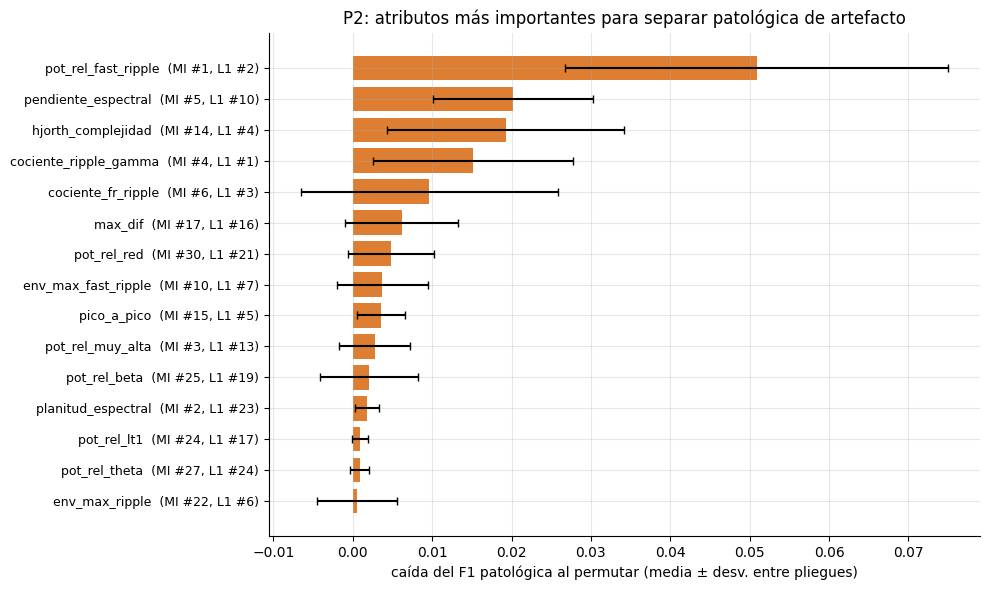

,permutación (media),permutación (desv.),puesto permutación,puesto info. mutua,puesto L1,veces en el top 5 (de 5 pliegues)
pot_rel_fast_ripple,0.0509,0.0241,1.0,1.0,2.0,5
pendiente_espectral,0.0202,0.0100,2.0,5.0,10.0,5
hjorth_complejidad,0.0193,0.0150,3.0,14.0,4.0,3
cociente_ripple_gamma,0.0151,0.0127,4.0,4.0,1.0,4
cociente_fr_ripple,0.0097,0.0162,5.0,6.0,3.0,2
max_dif,0.0061,0.0071,6.0,17.0,16.0,2
pot_rel_red,0.0048,0.0054,7.0,30.0,21.0,1
env_max_fast_ripple,0.0037,0.0057,8.0,10.0,7.0,1
pico_a_pico,0.0036,0.0031,9.0,15.0,5.0,0
pot_rel_muy_alta,0.0027,0.0045,10.0,3.0,13.0,1


In [27]:
ranking = pd.DataFrame({
    "permutación (media)": imp_perm.mean(axis=0),
    "permutación (desv.)": imp_perm.std(axis=0),
    "puesto permutación": pd.Series(imp_perm.mean(axis=0)).rank(ascending=False).to_numpy(),
    "puesto info. mutua": pd.Series(imp_mi.mean(axis=0)).rank(ascending=False).to_numpy(),
    "puesto L1": pd.Series(imp_l1.mean(axis=0)).rank(ascending=False).to_numpy(),
    "veces en el top 5 (de 5 pliegues)": (np.argsort(np.argsort(-imp_perm, axis=1), axis=1) < 5).sum(axis=0),
}, index=ATRIBUTOS).sort_values("permutación (media)", ascending=False)
ranking.to_csv(RESULTADOS / "p2_importancia_atributos.csv")

top = ranking.head(15).iloc[::-1]
etiquetas = [f"{n}  (MI #{f['puesto info. mutua']:.0f}, L1 #{f['puesto L1']:.0f})" for n, f in top.iterrows()]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(top)), top["permutación (media)"], xerr=top["permutación (desv.)"], color="#D55E00",
        alpha=0.8, capsize=3)
ax.set_yticks(range(len(top)), etiquetas, fontsize=9)
ax.set_xlabel("caída del F1 patológica al permutar (media ± desv. entre pliegues)")
ax.set_title("P2: atributos más importantes para separar patológica de artefacto")
plt.tight_layout()
plt.show()
ranking.head(10).round(4)

**Lectura de P2.**

- En la tarea binaria, el modelo separa patológica de artefacto con un F1 patológica de 0.89 ± 0.07 entre pliegues.
- El atributo más importante es la **potencia relativa en *fast ripple*** (250–500 Hz): primero por permutación y por información mutua, segundo con L1, y en el top 5 de los **cinco** pliegues.
- Le siguen la **pendiente espectral** (top 5 en los cinco pliegues), el **cociente *ripple*/gamma** (top 5 en cuatro pliegues y primero con L1) y la **complejidad de Hjorth** (top 5 en tres pliegues).
- El ranking *completo* por permutación es poco estable (Spearman medio = 0.38): muchos atributos tienen importancia casi nula y los atributos correlacionados se reparten la importancia. Pero los primeros puestos sí se repiten en todos los pliegues, y el filtro de información mutua es muy estable (≈ 0.95).

Interpretación: lo que separa a los artefactos de la actividad patológica es **cómo se reparte la energía en alta frecuencia** (los artefactos tienen proporcionalmente más energía en 250–500 Hz, como se vio en la sección 2.4) y la forma general del espectro, más que la forma de la onda en el tiempo.

### P3. ¿Un modelo entrenado en un hospital funciona en el otro?

Se usa el mejor modelo de P1. Primero se mide su desempeño **dentro de Mayo** con validación cruzada por paciente (para tener la referencia de ese hospital). Después se entrena con **todo FNUSA y se prueba en todo Mayo**, y al revés. La prueba externa se ejecuta **una sola vez**, sin ajustar nada con sus resultados. El atributo de potencia en la red se calculó en la frecuencia local de cada hospital (50 o 60 Hz).

In [28]:
modelo_p3 = MODELOS[MEJOR]
dentro_mayo = evaluar_cv(f"{MEJOR} (dentro de Mayo)", modelo_p3, X_m, y_m, k_m, **OPCIONES.get(MEJOR, {}))


def entrenar_probar(X_e, y_e, X_p):
    """Entrena con un hospital completo y predice el otro (prueba externa única).

    Usa las mismas opciones que en la validación cruzada (submuestra y pesos).
    """
    opciones = OPCIONES.get(MEJOR, {})
    idx = submuestra_estratificada(np.arange(len(y_e)), y_e, opciones.get("n_entrenamiento"))
    m = ajustar(modelo_p3, X_e[idx], y_e[idx], opciones.get("pesos", False))
    return m.predict(X_p)


pred_f_a_m = entrenar_probar(X_f, y_f, X_m)
pred_m_a_f = entrenar_probar(X_m, y_m, X_f)

p3 = pd.DataFrame({
    "F1 patológica: dentro del hospital": [resultados[MEJOR]["f1_global"], dentro_mayo["f1_global"]],
    "F1 patológica: en el otro hospital": [f1_patologica(y_m, pred_f_a_m), f1_patologica(y_f, pred_m_a_f)],
    "F1 macro: dentro": [resultados[MEJOR]["f1m_global"], dentro_mayo["f1m_global"]],
    "F1 macro: en el otro": [f1_score(y_m, pred_f_a_m, average="macro"), f1_score(y_f, pred_m_a_f, average="macro")],
}, index=["entrenado en FNUSA → prueba en Mayo", "entrenado en Mayo → prueba en FNUSA"])
p3.insert(2, "diferencia F1 patológica", p3.iloc[:, 1] - p3.iloc[:, 0])
# Precisión y sensibilidad de la clase patológica en la prueba externa
for nombre_p, (yy, pp) in {"FNUSA→Mayo": (y_m, pred_f_a_m), "Mayo→FNUSA": (y_f, pred_m_a_f)}.items():
    print(f"{nombre_p}: precisión patológica {precision_score(yy, pp, labels=['patologica'], average=None)[0]:.3f}, "
          f"sensibilidad patológica {recall_score(yy, pp, labels=['patologica'], average=None)[0]:.3f}")
p3.round(3).to_csv(RESULTADOS / "p3_generalizacion.csv")
print(p3.round(3).to_string())

por_clase = pd.DataFrame({
    "FNUSA→Mayo": f1_score(y_m, pred_f_a_m, labels=CLASES, average=None),
    "dentro de Mayo": f1_score(y_m, dentro_mayo["pred"], labels=CLASES, average=None),
    "Mayo→FNUSA": f1_score(y_f, pred_m_a_f, labels=CLASES, average=None),
    "dentro de FNUSA": f1_score(y_f, resultados[MEJOR]["pred"], labels=CLASES, average=None),
}, index=CLASES).round(3)
print("\nF1 por clase:")
por_clase

SVM (RBF) (dentro de Mayo)     F1 patológica = 0.602 ± 0.203 (global 0.565) | F1 macro = 0.569  [57 s]
FNUSA→Mayo: precisión patológica 0.345, sensibilidad patológica 0.863
Mayo→FNUSA: precisión patológica 0.787, sensibilidad patológica 0.737
                                     F1 patológica: dentro del hospital  F1 patológica: en el otro hospital  diferencia F1 patológica  F1 macro: dentro  F1 macro: en el otro
entrenado en FNUSA → prueba en Mayo                               0.695                               0.493                    -0.203             0.677                 0.479
entrenado en Mayo → prueba en FNUSA                               0.565                               0.761                     0.196             0.544                 0.760

F1 por clase:


,FNUSA→Mayo,dentro de Mayo,Mayo→FNUSA,dentro de FNUSA
fisiologica,0.635,0.315,0.723,0.669
patologica,0.493,0.565,0.761,0.695
artefacto,0.666,0.634,0.573,0.542
ruido_linea,0.123,0.661,0.985,0.799


**Lectura de P3.** La generalización **no es simétrica**:

- **FNUSA → Mayo:** el F1 patológica cae de 0.70 a 0.49. El modelo **sí encuentra** la actividad patológica de Mayo (sensibilidad 0.86), pero da muchas **falsas alarmas** (precisión 0.35): marca como patológicos muchos fragmentos fisiológicos de Mayo, una clase que en ese hospital es mucho más numerosa que la patológica (37 % frente a 10 %). En el F1 macro pesa además que el ruido de línea de 60 Hz casi no se reconoce.
- **Mayo → FNUSA:** el F1 patológica es de 0.76, **mayor** que dentro de FNUSA (0.70), con precisión y sensibilidad equilibradas (0.79 y 0.74). Mayo aporta 24 pacientes (más variedad), así que el modelo aprende fronteras más generales.

Conclusión: al cambiar de hospital, la detección de lo patológico se conserva, pero su precisión depende de la proporción de clases del hospital nuevo y del número de pacientes con que se entrena.

## 7. Comparación con deep learning

**Opción A (MLP sobre los atributos)** ya está en la comparación de la sección 5: usa los mismos atributos y pliegues que los demás modelos.

**Opción B (CNN 1D sobre la señal cruda).** Una red convolucional aprende directamente de la señal, sin atributos diseñados a mano. La pregunta es si eso supera a los atributos.

- **Datos:** el subconjunto de 40,539 fragmentos de FNUSA que prepara `scripts/preparar_subconjunto_cnn.py` (21 % de cada combinación pliegue × clase), submuestreados a 1250 Hz. Se conserva la banda de *fast ripple* (250–500 Hz).
- **Comparación justa:** la CNN usa **los mismos pliegues por paciente**, y el mejor modelo de atributos se reentrena **con exactamente los mismos fragmentos** del subconjunto. Se comparan pliegue por pliegue con la misma métrica (F1 patológica).

### 7.1 Mejor modelo de atributos en el subconjunto

In [29]:
ids_sub = pd.read_csv(DATOS / "cnn_subconjunto_ids.csv")
en_sub = datos["fnusa"]["segment_id"].isin(ids_sub["segment_id"]).to_numpy()
X_s, y_s, g_s, k_s = X_f[en_sub], y_f[en_sub], g_f[en_sub], k_f[en_sub]
sid_sub = datos["fnusa"].loc[en_sub, "segment_id"].to_numpy()
mismos = (pd.Series(k_s, index=sid_sub).sort_index() == ids_sub.set_index("segment_id")["pliegue"].sort_index()).all()
print(f"Subconjunto: {en_sub.sum():,} fragmentos; mismos pliegues que pliegues.csv: {mismos}")

atrib_sub = evaluar_cv(f"{MEJOR} (subconjunto)", MODELOS[MEJOR], X_s, y_s, k_s, **OPCIONES.get(MEJOR, {}))

Subconjunto: 40,539 fragmentos; mismos pliegues que pliegues.csv: True
SVM (RBF) (subconjunto)        F1 patológica = 0.720 ± 0.177 (global 0.694) | F1 macro = 0.622  [27 s]


### 7.2 Datos para la CNN

Cada fragmento se vuelve a normalizar (media 0, desviación 1) por separado: es una operación fija por fragmento, sin fugas. La forma de entrada es (fragmentos, 3750 muestras, 1 canal).

In [30]:
RUTA_CNN = RESULTADOS / "cnn_predicciones.csv"
CLASES_CNN = CLASES                                     # mismo orden de clases que el resto del notebook

if subconjunto is not None:
    x_cnn = subconjunto["x"].astype(np.float32)
    x_cnn = (x_cnn - x_cnn.mean(axis=1, keepdims=True)) / (x_cnn.std(axis=1, keepdims=True) + 1e-6)
    x_cnn = x_cnn[..., np.newaxis]
    y_cnn = np.array([CLASES_CNN.index(MAPA_CLASES[c]) for c in subconjunto["y"]])
    k_cnn = subconjunto["pliegue"]
    sid_cnn = subconjunto["segment_id"]
    # Verificación: los pliegues del .npz coinciden con los del resto del notebook
    assert (pd.Series(k_s, index=sid_sub).loc[sid_cnn].to_numpy() == k_cnn).all()
    print(f"x: {x_cnn.shape}; fragmentos por pliegue: {np.bincount(k_cnn)}")
else:
    print("No está datos/cnn_subconjunto_fnusa.npz: no se puede entrenar la CNN (ver README).")

x: (40539, 3750, 1); fragmentos por pliegue: [13673  6575  4123  5723 10445]


### 7.3 Arquitectura

- Cuatro bloques **convolución → normalización por lotes → ReLU → max pooling (÷4)**. Los primeros filtros (kernel de 7 muestras ≈ 6 ms) pueden captar oscilaciones rápidas; cada pooling amplía el campo receptivo hasta cubrir el fragmento.
- **Pooling global promedio**, una capa densa de 64 con *dropout* de 0.3 y salida *softmax* de 4 clases.
- **Entrenamiento:** Adam (tasa 1e-3), 15 épocas fijas, lotes de 128 y pesos por clase balanceados, como en los modelos de atributos. No se usa parada temprana con un conjunto de validación al azar, porque mezclaría pacientes (mismo criterio que en la sección 4).

La CNN se entrena si TensorFlow está disponible; con GPU tarda ~15 minutos. Si no hay TensorFlow, se cargan las predicciones de una ejecución anterior guardadas en `resultados/cnn_predicciones.csv`.

In [31]:
try:
    import tensorflow as tf
    TF_DISPONIBLE = True
    GPUS = tf.config.list_physical_devices("GPU")
    print(f"TensorFlow {tf.__version__}; GPU: {GPUS or 'no disponible (el entrenamiento será lento)'}")
except ImportError:
    TF_DISPONIBLE = False
    print("TensorFlow no está instalado: se usarán las predicciones guardadas de la CNN, si existen.")

ENTRENAR_CNN = TF_DISPONIBLE and subconjunto is not None


def crear_cnn(longitud=3750, n_clases=4):
    """CNN 1D para clasificar fragmentos de iEEG de 3 s a 1250 Hz."""
    entrada = tf.keras.Input(shape=(longitud, 1))
    h = entrada
    for filtros, kernel in [(32, 7), (64, 7), (128, 5), (128, 5)]:
        h = tf.keras.layers.Conv1D(filtros, kernel, padding="same", use_bias=False)(h)
        h = tf.keras.layers.BatchNormalization()(h)
        h = tf.keras.layers.ReLU()(h)
        h = tf.keras.layers.MaxPooling1D(4)(h)
    h = tf.keras.layers.GlobalAveragePooling1D()(h)
    h = tf.keras.layers.Dropout(0.3)(h)
    h = tf.keras.layers.Dense(64, activation="relu")(h)
    salida = tf.keras.layers.Dense(n_clases, activation="softmax")(h)
    modelo = tf.keras.Model(entrada, salida)
    modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


if ENTRENAR_CNN:
    tf.keras.utils.set_random_seed(SEMILLA)
    crear_cnn().summary()

TensorFlow 2.21.0; GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 3750, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 3750, 32)       │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 3750, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 3750, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 937, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 937, 64)        │        14,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 937, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 937, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 234, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 234, 128)       │        40,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 234, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 234, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 58, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 58, 128)        │        81,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 58, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 58, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 14, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147,364 (575.64 KB)

 Trainable params: 146,660 (572.89 KB)

 Non-trainable params: 704 (2.75 KB)

### 7.4 Validación cruzada de la CNN con los pliegues por paciente

En cada pliegue se entrena una red nueva con los otros cuatro y se predice el pliegue que quedó fuera.

Pliegue 0: F1 patológica = 0.814, F1 macro = 0.584  (104 s)
Pliegue 1: F1 patológica = 0.902, F1 macro = 0.847  (113 s)
Pliegue 2: F1 patológica = 0.695, F1 macro = 0.336  (114 s)
Pliegue 3: F1 patológica = 0.788, F1 macro = 0.416  (105 s)
Pliegue 4: F1 patológica = 0.422, F1 macro = 0.487  (106 s)
Tiempo total: 9.0 min
Predicciones guardadas en resultados/cnn_predicciones.csv


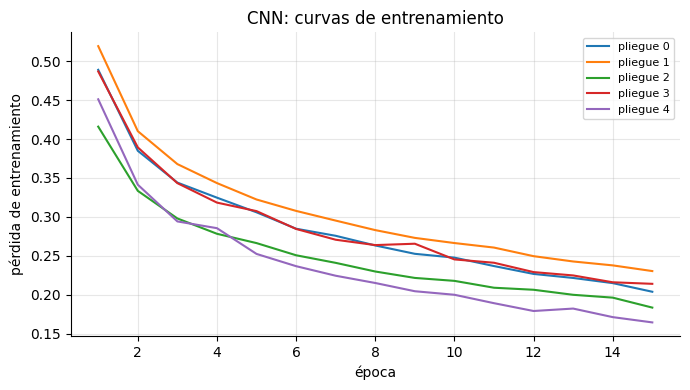

In [32]:
EPOCAS, LOTE = 15, 128

if ENTRENAR_CNN:
    prob_cnn = np.zeros((len(y_cnn), len(CLASES_CNN)), dtype=np.float32)
    historias = []
    t0_cnn = time.time()
    for k in range(5):
        t0 = time.time()
        entr, prueba = k_cnn != k, k_cnn == k
        tf.keras.utils.set_random_seed(SEMILLA + k)
        pesos_k = compute_sample_weight("balanced", y_cnn[entr])
        pesos_clase = {int(c): float(pesos_k[y_cnn[entr] == c][0]) for c in np.unique(y_cnn[entr])}
        red = crear_cnn()
        hist = red.fit(x_cnn[entr], y_cnn[entr], epochs=EPOCAS, batch_size=LOTE,
                       class_weight=pesos_clase, verbose=0)
        prob_cnn[prueba] = red.predict(x_cnn[prueba], batch_size=512, verbose=0)
        historias.append(hist.history)
        pred_k = np.array(CLASES_CNN)[prob_cnn[prueba].argmax(axis=1)]
        real_k = np.array(CLASES_CNN)[y_cnn[prueba]]
        print(f"Pliegue {k}: F1 patológica = {f1_patologica(real_k, pred_k):.3f}, "
              f"F1 macro = {f1_score(real_k, pred_k, average='macro'):.3f}  ({time.time() - t0:.0f} s)")
    print(f"Tiempo total: {(time.time() - t0_cnn) / 60:.1f} min")

    # Se guardan las predicciones para poder reutilizarlas sin volver a entrenar
    guardar = pd.DataFrame({"segment_id": sid_cnn, "pliegue": k_cnn,
                            "real": np.array(CLASES_CNN)[y_cnn],
                            "pred": np.array(CLASES_CNN)[prob_cnn.argmax(axis=1)]})
    for i, c in enumerate(CLASES_CNN):
        guardar[f"prob_{c}"] = prob_cnn[:, i].round(4)
    guardar.to_csv(RUTA_CNN, index=False)
    print("Predicciones guardadas en", RUTA_CNN)

    fig, ax = plt.subplots(figsize=(7, 4))
    for k, h in enumerate(historias):
        ax.plot(range(1, EPOCAS + 1), h["loss"], label=f"pliegue {k}")
    ax.set_xlabel("época")
    ax.set_ylabel("pérdida de entrenamiento")
    ax.set_title("CNN: curvas de entrenamiento")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
elif RUTA_CNN.exists():
    print(f"Se cargan las predicciones guardadas de la CNN: {RUTA_CNN}")
else:
    print("No hay TensorFlow ni predicciones guardadas: la comparación de la sección 7.5 no se puede hacer.")

### 7.5 CNN frente al mejor modelo de atributos

                              SVM (RBF) (atributos)  CNN 1D (señal cruda)  diferencia (CNN − atributos)
F1 de la clase patológica                                                                              
pliegue 0                                     0.785                 0.814                         0.029
pliegue 1                                     0.839                 0.902                         0.063
pliegue 2                                     0.649                 0.695                         0.046
pliegue 3                                     0.914                 0.788                        -0.125
pliegue 4                                     0.412                 0.422                         0.010
media                                         0.720                 0.724                         0.005
desv. est.                                    0.177                 0.165                           NaN
global (fuera de pliegue)                     0.694             

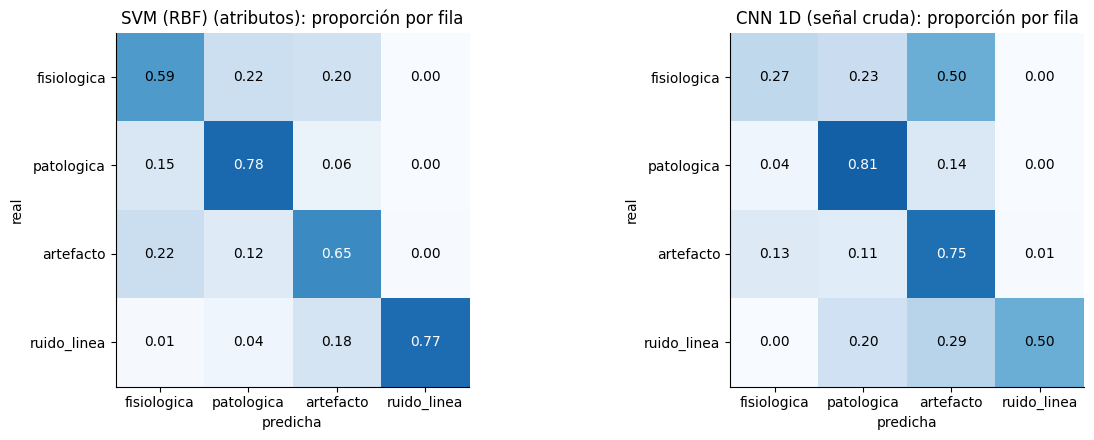

F1 por clase (fuera de pliegue):
             atributos    CNN
fisiologica      0.671  0.405
patologica       0.694  0.693
artefacto        0.542  0.423
ruido_linea      0.861  0.661


In [33]:
if RUTA_CNN.exists():
    cnn = pd.read_csv(RUTA_CNN).set_index("segment_id").loc[sid_sub]
    pred_cnn = cnn["pred"].map(lambda c: MAPA_CLASES.get(c, c)).to_numpy()
    f1_cnn = np.array([f1_patologica(y_s[k_s == k], pred_cnn[k_s == k]) for k in range(5)])
    dl = pd.DataFrame({
        f"{MEJOR} (atributos)": atrib_sub["f1_pliegues"],
        "CNN 1D (señal cruda)": f1_cnn,
    }, index=[f"pliegue {k}" for k in range(5)])
    dl.loc["media"] = dl.iloc[:5].mean()
    dl.loc["desv. est."] = dl.iloc[:5].std(ddof=0)
    dl.loc["global (fuera de pliegue)"] = [atrib_sub["f1_global"], f1_patologica(y_s, pred_cnn)]
    dl.loc["F1 macro global (secundaria)"] = [atrib_sub["f1m_global"], f1_score(y_s, pred_cnn, average="macro")]
    dl["diferencia (CNN − atributos)"] = dl.iloc[:, 1] - dl.iloc[:, 0]
    dl.loc["desv. est.", "diferencia (CNN − atributos)"] = np.nan          # no tiene sentido restar desviaciones
    dl.index.name = "F1 de la clase patológica"
    dl.round(3).to_csv(RESULTADOS / "comparacion_deep_learning.csv")
    print(dl.round(3).to_string())

    # Intervalo de la diferencia por bootstrap de pacientes, como en la sección 5.2
    boot_dl = bootstrap_pacientes({"atributos": atrib_sub["pred"], "cnn": pred_cnn}, y_s, g_s)
    dif = boot_dl["cnn"] - boot_dl["atributos"]
    print(f"\nDiferencia CNN − atributos en F1 patológica: {dl.iloc[7, 2]:+.3f} "
          f"(IC 95 % por bootstrap de pacientes: {np.percentile(dif, 2.5):+.3f} a {np.percentile(dif, 97.5):+.3f})")

    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, (nom, pr) in zip(ejes, [(f"{MEJOR} (atributos)", atrib_sub["pred"]), ("CNN 1D (señal cruda)", pred_cnn)]):
        cm_dl = confusion_matrix(y_s, pr, labels=CLASES)
        cm_dl = cm_dl / cm_dl.sum(axis=1, keepdims=True)
        ax.imshow(cm_dl, cmap="Blues", vmin=0, vmax=1)
        for i in range(4):
            for j in range(4):
                ax.text(j, i, f"{cm_dl[i, j]:.2f}", ha="center", va="center",
                        color="white" if cm_dl[i, j] > 0.6 else "black")
        ax.set_xticks(range(4), CLASES)
        ax.set_yticks(range(4), CLASES)
        ax.set_xlabel("predicha")
        ax.set_ylabel("real")
        ax.grid(False)
        ax.set_title(f"{nom}: proporción por fila")
    plt.tight_layout()
    plt.show()

    print("F1 por clase (fuera de pliegue):")
    print(pd.DataFrame({"atributos": f1_score(y_s, atrib_sub["pred"], labels=CLASES, average=None),
                        "CNN": f1_score(y_s, pred_cnn, labels=CLASES, average=None)},
                       index=CLASES).round(3).to_string())
else:
    print("Sin predicciones de la CNN: ejecutar este notebook en Colab con GPU (ver README).")

## 8. Extensiones: librerías especializadas, *boosting*, optuna, SHAP y braindecode

Esta sección amplía las secciones 4 a 7 **sin cambiar sus resultados**. Trabaja con el **subconjunto de 40,539 fragmentos de FNUSA a 1250 Hz** de la sección 7 (21 % de cada combinación pliegue × clase) y **los mismos 5 pliegues por paciente**, así que sus cifras se comparan con el SVM y la CNN de la sección 7, no con la tabla completa de la sección 5. Como el subconjunto es solo de FNUSA, **no responde P3**.

| Subsección | Librería | Pregunta |
|---|---|---|
| 8.1 | specparam, antropy, MNE, EPyCom, TSFEL | ¿Qué atributos nuevos se calcularon? |
| 8.2 | scikit-learn, LightGBM, XGBoost | P1: ¿los atributos nuevos o el *boosting* superan al SVM con los 30 atributos? |
| 8.3 | LightGBM | ¿Qué librería aporta más? |
| 8.4 | optuna | ¿Ajustar hiperparámetros con validación anidada por paciente mejora al mejor modelo? |
| 8.5 | SHAP | P2: ¿qué atributos separan lo patológico de los artefactos? |
| 8.6 | braindecode | ¿Redes publicadas para EEG superan a la CNN propia y a los atributos? |

**Pasos previos.** Los atributos nuevos se calculan aparte con `scripts/extraer_atributos_extendidos.py` (~100 min con 14 procesos; ver el README) y se guardan en `datos/atributos_extendidos_subconjunto.csv.gz`. Esta sección los carga.

**Tiempo.** En una computadora con 16 hilos, 8.1 a 8.5 tardan ~20 min (13 en optuna); en Colab, con 2 núcleos, bastante más (se puede bajar `N_INTENTOS_OPTUNA`). En 8.6, si ya hay predicciones guardadas de las redes elegidas (`REDES_BD`), se cargan; si no, se entrenan con GPU o, con `BD_EN_CPU = True`, en el procesador (medido en un i7 de 13.ª generación: ~1 h EEGNet, ~2 h ShallowFBCSPNet y ~6 h Deep4Net).

In [34]:
# --- Parámetros de la sección 8 ---
N_INTENTOS_OPTUNA = 25      # intentos de optuna por pliegue externo
EPOCAS_BD = 15              # épocas de las redes de braindecode (mismas que la CNN de la sección 7)
PRUEBA_RAPIDA = False        # True: versión mínima para comprobar que todo corre (no da resultados válidos)
REDES_BD = ["EEGNet"]          # redes de 8.6; en CPU, "ShallowFBCSPNet" tarda ~2 h y "Deep4Net" ~6 h (agregarlas con GPU)
BD_EN_CPU = True               # True: 8.6 entrena aunque no haya GPU (~1 h EEGNet, ~2 h ShallowFBCSPNet en un i7)

if EN_COLAB:   # librerías que no vienen en Colab por omisión
    get_ipython().run_line_magic("pip", "install -q lightgbm optuna shap braindecode")

import lightgbm as lgb
import optuna
import shap
import xgboost as xgb
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder, QuantileTransformer

optuna.logging.set_verbosity(optuna.logging.WARNING)
FIGURAS = RESULTADOS / "figuras_extensiones"
FIGURAS.mkdir(parents=True, exist_ok=True)
COLOR_GRUPO = {"base": "#999999", "specparam": "#E69F00", "antropy": "#56B4E9", "MNE": "#009E73",
               "EPyCom": "#D55E00", "TSFEL": "#CC79A7"}
print(f"lightgbm {lgb.__version__} | xgboost {xgb.__version__} | optuna {optuna.__version__} | shap {shap.__version__}")

C:\Users\marey\AppData\Local\Temp\claude\5175440b288e3034\c86869eb-09f7-4093-ada9-c7bd85eb0c1a\scratchpad\venv_medicion\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


lightgbm 4.7.0 | xgboost 3.4.1 | optuna 5.1.0 | shap 0.54.1


### 8.1 Datos: los 30 atributos originales y los atributos nuevos

Se unen, por `segment_id`, los fragmentos del subconjunto con su pliegue, su paciente, su clase, los 30 atributos de la sección 1 y los atributos nuevos. Cada librería se identifica por el prefijo de sus columnas:

| Prefijo | Librería | Qué mide |
|---|---|---|
| `sp_` | **specparam** | Modelo del espectro: componente aperiódica 1/f con codo (*offset*, codo, exponente) y hasta 6 picos oscilatorios |
| `ant_` | **antropy** | Entropías (permutación, espectral, SVD, muestral, aproximada) y dimensiones fractales (Petrosian, Katz, Higuchi, DFA) |
| `mne_` | **MNE** | Potencia relativa por banda con el estimador *multitaper*, menos ruidoso que Welch |
| `epy_` | **EPyCom** | Detectores publicados de HFO (*line length*, RMS y Hilbert) y de espigas (Barkmeier): número, duración y amplitud de eventos |
| `tsfel_` | **TSFEL** | Atributos genéricos de series de tiempo: estadísticos, temporales y espectrales (sin el dominio fractal, que tarda ~7 s por fragmento) |

In [35]:
atr_base = pd.read_csv(DATOS / "atributos_fnusa.csv.gz")
atr_ext = pd.read_csv(DATOS / "atributos_extendidos_subconjunto.csv.gz")
segmentos_x = pd.read_csv(DATOS / "segments_fnusa.csv", usecols=["segment_id", "patient_id", "category_name"])
dx = (pd.read_csv(DATOS / "cnn_subconjunto_ids.csv")
      .merge(segmentos_x, on="segment_id", validate="one_to_one")
      .merge(atr_base, on="segment_id", validate="one_to_one")
      .merge(atr_ext, on="segment_id", validate="one_to_one"))
dx = dx.assign(clase=dx["category_name"].map(MAPA_CLASES))

if PRUEBA_RAPIDA:   # 100 fragmentos por pliegue y clase, solo para comprobar que el código corre
    dx = dx.sample(frac=1, random_state=SEMILLA)
    dx = dx[dx.groupby(["pliegue", "clase"]).cumcount() < 100].sort_index().reset_index(drop=True)

ATRIBUTOS_BASE = [c for c in atr_base.columns if c not in ("segment_id", "md5", "media", "desv_est")]
PREFIJOS = {"specparam": "sp_", "antropy": "ant_", "MNE": "mne_", "EPyCom": "epy_", "TSFEL": "tsfel_"}
GRUPOS = {gr: [c for c in atr_ext.columns if c.startswith(p)] for gr, p in PREFIJOS.items()}
ATRIBUTOS_EXT = [c for cols in GRUPOS.values() for c in cols]


def grupo_de(columna):
    """Librería de origen de un atributo (o 'base' para los 30 originales)."""
    return next((gr for gr, p in PREFIJOS.items() if columna.startswith(p)), "base")


print(f"{len(dx):,} fragmentos, {dx['patient_id'].nunique()} pacientes")
print(f"Atributos: {len(ATRIBUTOS_BASE)} originales + {len(ATRIBUTOS_EXT)} nuevos "
      + str({gr: len(c) for gr, c in GRUPOS.items()}))
assert (dx.groupby("patient_id")["pliegue"].nunique() == 1).all(), "un paciente en dos pliegues"
pd.crosstab(dx["pliegue"], dx["clase"])[CLASES]

40,539 fragmentos, 14 pacientes
Atributos: 30 originales + 196 nuevos {'specparam': 10, 'antropy': 9, 'MNE': 9, 'EPyCom': 12, 'TSFEL': 156}


C:\Users\marey\AppData\Local\Temp\ipykernel_25344\1359447308.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dx = dx.assign(clase=dx["category_name"].map(MAPA_CLASES))


clase,fisiologica,patologica,artefacto,ruido_linea
pliegue,,,,
0,8589,3244,1411,429
1,3293,2010,1272,0
2,202,2144,1777,0
3,1145,2016,1065,1497
4,6627,1600,1312,906


**Calidad de los atributos nuevos.** Se revisan valores faltantes, infinitos y columnas sin variación antes de modelar.

In [36]:
faltantes = dx[ATRIBUTOS_EXT].isna().mean()
constantes = [c for c in ATRIBUTOS_EXT if dx[c].nunique(dropna=True) <= 1]
print("Columnas con faltantes (proporción):", faltantes[faltantes > 0].round(3).to_dict())
print(f"Columnas constantes ({len(constantes)}):", constantes)
print("Valores infinitos:", np.isinf(dx[ATRIBUTOS_EXT].to_numpy(float)).sum())
print("Rango de sp_knee:", dx["sp_knee"].min(), "a", dx["sp_knee"].max())

Columnas con faltantes (proporción): {'sp_pico_mayor_frec': 0.021}
Columnas constantes (10): ['tsfel_ecdf_0', 'tsfel_ecdf_1', 'tsfel_ecdf_2', 'tsfel_ecdf_3', 'tsfel_ecdf_4', 'tsfel_ecdf_5', 'tsfel_ecdf_6', 'tsfel_ecdf_7', 'tsfel_ecdf_8', 'tsfel_ecdf_9']
Valores infinitos: 0
Rango de sp_knee: -5.82122093773487 a 1751454128823848.5


**Decisiones.**

- `sp_pico_mayor_frec` falta cuando specparam no encuentra picos. LightGBM y XGBoost manejan los faltantes por sí mismos; para el SVM se imputa la mediana **dentro de cada pliegue** (`SimpleImputer` en el `Pipeline`).
- Las columnas constantes de TSFEL (ECDF) no varían porque cada señal viene normalizada. Se quitan con `VarianceThreshold` dentro del `Pipeline`, sin mirar los datos de prueba.
- Varios atributos nuevos tienen colas extremas (por ejemplo, `sp_knee`, cuando el ajuste del codo es inestable). Para el SVM se usa `QuantileTransformer`, ajustado solo con el entrenamiento, que lleva cada atributo a una distribución normal sin depender de los valores extremos. Los árboles no lo necesitan.

### 8.2 P1 con los atributos nuevos: SVM, LightGBM y XGBoost

Mismo procedimiento que la sección 4: pliegues fijos por paciente, F1 de la clase patológica (media ± desv. entre pliegues y global), F1 macro como secundaria e intervalos por *bootstrap* de pacientes (sección 5.2). El SVM se entrena, como allí, con una submuestra estratificada de 10 mil fragmentos por pliegue.

| Modelo | Preprocesamiento | Por qué |
|---|---|---|
| SVM RBF, 30 atributos | estandarización | Referencia: el mejor modelo de la sección 5, en este subconjunto (sección 7.1) |
| SVM RBF, 30 atributos | imputación + varianza + cuantiles | Control: separa el efecto del preprocesamiento del de los atributos nuevos |
| SVM RBF, base + nuevos | imputación + varianza + cuantiles | ¿Los atributos nuevos ayudan al mismo modelo? |
| **LightGBM** | ninguno (maneja faltantes) | *Boosting* rápido, con regularización por hojas mínimas |
| **XGBoost** | ninguno | Otra implementación de *boosting*; pesos por clase con `sample_weight` |

Todos usan pesos por clase balanceados. LightGBM y XGBoost: 300 árboles, tasa de aprendizaje 0.05, sin parada temprana (apartaría fragmentos del mismo paciente).

In [37]:
def matriz_x(columnas):
    """Atributos del subconjunto como matriz; log10 fijo en los originales con cola larga (sección 2.4)."""
    M = dx[columnas].astype(float).copy()
    log = [c for c in columnas if c in COLUMNAS_LOG]
    M[log] = np.log10(M[log] + 1e-8)
    return M.to_numpy()


y_x, g_x, k_x = dx["clase"].to_numpy(), dx["patient_id"].to_numpy(), dx["pliegue"].to_numpy()
CONJUNTOS = {"base (30)": ATRIBUTOS_BASE, "nuevos": ATRIBUTOS_EXT, "base + nuevos": ATRIBUTOS_BASE + ATRIBUTOS_EXT}
X_x = {nombre: matriz_x(cols) for nombre, cols in CONJUNTOS.items()}


def evaluar_x(nombre, modelo, Xm, n_entrenamiento=None):
    """Validación cruzada en el subconjunto con los pliegues fijos (como evaluar_cv de la sección 4.1)."""
    pred = np.empty(len(y_x), dtype=object)
    f1s, f1ms = [], []
    t0 = time.time()
    for pl in np.unique(k_x):
        entr, prueba = k_x != pl, k_x == pl
        idx = submuestra_estratificada(np.flatnonzero(entr), y_x, n_entrenamiento)
        m = clone(modelo).fit(Xm[idx], y_x[idx])
        pred[prueba] = m.predict(Xm[prueba])
        f1s.append(f1_patologica(y_x[prueba], pred[prueba]))
        f1ms.append(f1_score(y_x[prueba], pred[prueba], average="macro"))
    res = {"modelo": nombre, "pred": pred, "segundos": time.time() - t0, "f1_pliegues": np.array(f1s),
           "f1_global": f1_patologica(y_x, pred), "f1m_pliegues": np.array(f1ms)}
    print(f"{nombre:38s} F1 patológica = {res['f1_pliegues'].mean():.3f} ± {res['f1_pliegues'].std():.3f} "
          f"(global {res['f1_global']:.3f}) | F1 macro = {res['f1m_pliegues'].mean():.3f}  [{res['segundos']:.0f} s]")
    return res


class XGBBalanceado(BaseEstimator, ClassifierMixin):
    """XGBoost con etiquetas de texto y pesos por clase balanceados (XGBoost no tiene class_weight)."""

    def __init__(self, n_estimators=300, learning_rate=0.05, max_depth=6):
        self.n_estimators, self.learning_rate, self.max_depth = n_estimators, learning_rate, max_depth

    def fit(self, X_, y_):
        self.codificador_ = LabelEncoder().fit(y_)
        self.classes_ = self.codificador_.classes_
        self.modelo_ = xgb.XGBClassifier(n_estimators=self.n_estimators, learning_rate=self.learning_rate,
                                         max_depth=self.max_depth, tree_method="hist", n_jobs=-1,
                                         random_state=SEMILLA)
        self.modelo_.fit(X_, self.codificador_.transform(y_), sample_weight=compute_sample_weight("balanced", y_))
        return self

    def predict(self, X_):
        return self.codificador_.inverse_transform(self.modelo_.predict(X_))


PARAMS_LGBM = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight="balanced",
                   random_state=SEMILLA, n_jobs=-1, verbose=-1)


def lgbm(**params):
    return lgb.LGBMClassifier(**{**PARAMS_LGBM, **params})


def svm_estandar():
    return make_pipeline(StandardScaler(), SVC(C=1.0, class_weight="balanced", random_state=SEMILLA))


def svm_robusta():
    return make_pipeline(SimpleImputer(strategy="median"), VarianceThreshold(),
                         QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEMILLA),
                         StandardScaler(), SVC(C=1.0, class_weight="balanced", random_state=SEMILLA))


N_SVM = 10_000
res_x = {}
for nombre, modelo, conjunto, n_e in [
    ("SVM · base (30)", svm_estandar(), "base (30)", N_SVM),
    ("SVM · base (30), cuantiles", svm_robusta(), "base (30)", N_SVM),
    ("SVM · base + nuevos", svm_robusta(), "base + nuevos", N_SVM),
    ("LightGBM · base (30)", lgbm(), "base (30)", None),
    ("LightGBM · nuevos", lgbm(), "nuevos", None),
    ("LightGBM · base + nuevos", lgbm(), "base + nuevos", None),
    ("XGBoost · base + nuevos", XGBBalanceado(), "base + nuevos", None),
]:
    res_x[nombre] = evaluar_x(nombre, modelo, X_x[conjunto], n_e)

SVM · base (30)                        F1 patológica = 0.720 ± 0.177 (global 0.694) | F1 macro = 0.622  [20 s]


SVM · base (30), cuantiles             F1 patológica = 0.731 ± 0.184 (global 0.706) | F1 macro = 0.629  [21 s]


SVM · base + nuevos                    F1 patológica = 0.751 ± 0.180 (global 0.731) | F1 macro = 0.619  [43 s]


LightGBM · base (30)                   F1 patológica = 0.704 ± 0.177 (global 0.677) | F1 macro = 0.508  [13 s]


LightGBM · nuevos                      F1 patológica = 0.747 ± 0.181 (global 0.719) | F1 macro = 0.610  [38 s]


LightGBM · base + nuevos               F1 patológica = 0.740 ± 0.184 (global 0.709) | F1 macro = 0.602  [42 s]


XGBoost · base + nuevos                F1 patológica = 0.740 ± 0.186 (global 0.709) | F1 macro = 0.620  [113 s]


Cada modelo se compara con la referencia (SVM con los 30 atributos) con un intervalo por *bootstrap* de pacientes de la **diferencia** de F1 patológica global: si no incluye el 0, la diferencia no se explica por qué pacientes tocaron.

In [38]:
REFERENCIA = "SVM · base (30)"


def tabla_comparacion(res, referencia=REFERENCIA):
    """Métricas de cada modelo y diferencia contra la referencia con IC 95 % por bootstrap de pacientes."""
    boot = bootstrap_pacientes({n: r["pred"] for n, r in res.items()}, y_x, g_x)
    filas = []
    for n, r in res.items():
        d = boot[n] - boot[referencia]
        filas.append({
            "modelo": n,
            "F1 pat. (media)": r["f1_pliegues"].mean(), "desv.": r["f1_pliegues"].std(),
            "F1 pat. global": r["f1_global"],
            "precisión": precision_score(y_x, r["pred"], labels=["patologica"], average=None, zero_division=0)[0],
            "sensibilidad": recall_score(y_x, r["pred"], labels=["patologica"], average=None, zero_division=0)[0],
            "F1 macro (media)": r["f1m_pliegues"].mean(),
            "Δ global vs. ref.": r["f1_global"] - res[referencia]["f1_global"],
            "IC 95 % Δ inf.": np.percentile(d, 2.5), "IC 95 % Δ sup.": np.percentile(d, 97.5),
            "pliegues mejor que ref.": int((r["f1_pliegues"] > res[referencia]["f1_pliegues"]).sum()),
            "segundos": r["segundos"],
        })
    return pd.DataFrame(filas).set_index("modelo").round(3)


tabla_x = tabla_comparacion(res_x)
tabla_x.to_csv(RESULTADOS / "ext_comparacion_modelos.csv")
tabla_x

,F1 pat. (media),desv.,F1 pat. global,precisión,sensibilidad,F1 macro (media),Δ global vs. ref.,IC 95 % Δ inf.,IC 95 % Δ sup.,pliegues mejor que ref.,segundos
modelo,,,,,,,,,,,
SVM · base (30),0.720,0.177,0.694,0.622,0.784,0.622,0.000,0.000,0.000,0,20.334
"SVM · base (30), cuantiles",0.731,0.184,0.706,0.638,0.790,0.629,0.012,0.003,0.024,4,20.901
SVM · base + nuevos,0.751,0.180,0.731,0.670,0.804,0.619,0.037,0.023,0.052,5,43.113
LightGBM · base (30),0.704,0.177,0.677,0.608,0.765,0.508,-0.016,-0.050,0.006,3,12.793
LightGBM · nuevos,0.747,0.181,0.719,0.645,0.812,0.610,0.025,0.013,0.042,5,38.165
LightGBM · base + nuevos,0.740,0.184,0.709,0.629,0.811,0.602,0.015,0.002,0.033,4,42.093
XGBoost · base + nuevos,0.740,0.186,0.709,0.630,0.810,0.620,0.015,-0.003,0.035,4,113.253


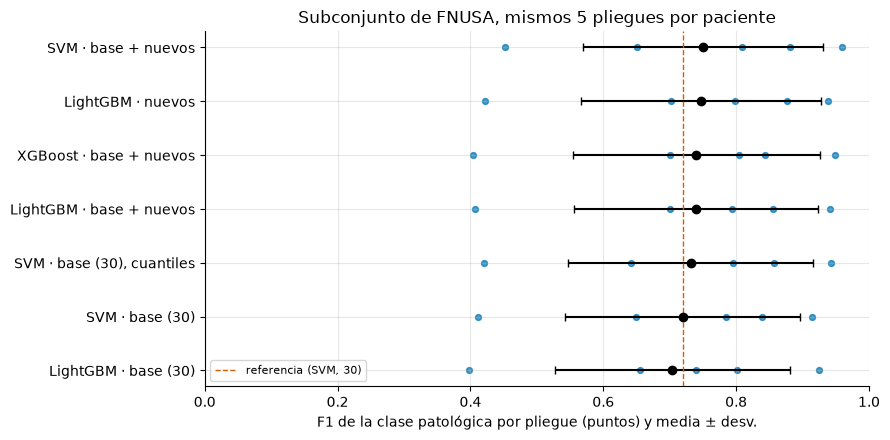

In [39]:
orden_x = tabla_x.sort_values("F1 pat. (media)").index
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, n in enumerate(orden_x):
    f = res_x[n]["f1_pliegues"]
    ax.scatter(f, np.full(len(f), i), s=18, alpha=0.7, color="#0072B2")
    ax.errorbar(f.mean(), i, xerr=f.std(), fmt="o", color="black", capsize=3)
ax.axvline(res_x[REFERENCIA]["f1_pliegues"].mean(), color="#D55E00", ls="--", lw=1, label="referencia (SVM, 30)")
ax.set_yticks(range(len(orden_x)), orden_x)
ax.set_xlabel("F1 de la clase patológica por pliegue (puntos) y media ± desv.")
ax.set_xlim(0, 1)
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Subconjunto de FNUSA, mismos 5 pliegues por paciente")
plt.tight_layout()
plt.savefig(FIGURAS / "comparacion_modelos_extendidos.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura.**

- **La referencia reproduce la sección 7.1.** El SVM con los 30 atributos obtiene 0.720 ± 0.177 (global 0.694) en el subconjunto, las mismas cifras de allí.
- **El mejor modelo es el mismo SVM con los atributos nuevos:** 0.751 ± 0.180 (global 0.731). Mejora en los **5 pliegues** y la diferencia global es de +0.037 (IC 95 %: +0.023 a +0.052). Sube sobre todo la precisión (0.62 → 0.67) y algo la sensibilidad (0.78 → 0.80): hay menos falsas alarmas.
- **Parte de la mejora viene del preprocesamiento, no de los atributos.** El SVM con solo los 30 atributos y la transformación por cuantiles ya sube a 0.731 (+0.012, IC +0.003 a +0.024). Los atributos nuevos aportan el resto, alrededor de +0.025.
- **El *boosting* no supera al SVM.** LightGBM con los 30 atributos queda por debajo (0.704; −0.016, IC −0.050 a +0.006). Con todos los atributos, LightGBM y XGBoost empatan en 0.740 (+0.015; el intervalo de XGBoost incluye el 0). LightGBM con *solo* los atributos nuevos (0.747) rinde igual o mejor que con todos: buena parte de la información de los 30 originales ya está en los nuevos.
- **La F1 macro no cambia** (0.62 en ambos SVM): la mejora se concentra en la clase patológica.
- **La mejora es mucho menor que la variación entre pacientes.** Las diferencias entre modelos son de 0.02 a 0.04, mientras que la desviación entre pliegues es de ~0.18, y el pliegue más difícil se queda en 0.40–0.45 con todos los modelos.

### 8.3 ¿Qué librería aporta más?

Se agrega **un grupo de atributos a la vez** a los 30 originales y se entrena LightGBM con los mismos pliegues. La diferencia contra LightGBM con solo los 30 atributos (con su intervalo por *bootstrap* de pacientes) indica cuánto aporta cada librería por sí sola.

In [40]:
aporte = {"LightGBM · base (30)": res_x["LightGBM · base (30)"]}
for grupo, cols in GRUPOS.items():
    nombre = f"LightGBM · base + {grupo}"
    aporte[nombre] = evaluar_x(nombre, lgbm(), matriz_x(ATRIBUTOS_BASE + cols))
tabla_aporte = tabla_comparacion(aporte, referencia="LightGBM · base (30)")
tabla_aporte.insert(0, "n atributos", [len(ATRIBUTOS_BASE)] + [len(ATRIBUTOS_BASE) + len(c) for c in GRUPOS.values()])
tabla_aporte.to_csv(RESULTADOS / "ext_aporte_por_libreria.csv")
tabla_aporte

LightGBM · base + specparam            F1 patológica = 0.707 ± 0.180 (global 0.678) | F1 macro = 0.590  [12 s]


LightGBM · base + antropy              F1 patológica = 0.703 ± 0.165 (global 0.682) | F1 macro = 0.541  [10 s]


LightGBM · base + MNE                  F1 patológica = 0.706 ± 0.178 (global 0.678) | F1 macro = 0.508  [10 s]


LightGBM · base + EPyCom               F1 patológica = 0.710 ± 0.170 (global 0.686) | F1 macro = 0.539  [12 s]


LightGBM · base + TSFEL                F1 patológica = 0.731 ± 0.181 (global 0.707) | F1 macro = 0.525  [42 s]


,n atributos,F1 pat. (media),desv.,F1 pat. global,precisión,sensibilidad,F1 macro (media),Δ global vs. ref.,IC 95 % Δ inf.,IC 95 % Δ sup.,pliegues mejor que ref.,segundos
modelo,,,,,,,,,,,,
LightGBM · base (30),30,0.704,0.177,0.677,0.608,0.765,0.508,0.000,0.000,0.000,0,12.793
LightGBM · base + specparam,40,0.707,0.180,0.678,0.601,0.777,0.590,0.000,-0.022,0.021,2,12.486
LightGBM · base + antropy,39,0.703,0.165,0.682,0.607,0.779,0.541,0.005,-0.025,0.028,3,10.282
LightGBM · base + MNE,39,0.706,0.178,0.678,0.609,0.765,0.508,0.001,-0.003,0.005,4,10.482
LightGBM · base + EPyCom,42,0.710,0.170,0.686,0.611,0.784,0.539,0.009,-0.009,0.030,2,11.743
LightGBM · base + TSFEL,186,0.731,0.181,0.707,0.639,0.790,0.525,0.029,0.013,0.052,5,41.753


**Lectura.**

- **Solo TSFEL aporta de forma clara:** con sus 156 atributos, LightGBM pasa de 0.704 a 0.731 (+0.029 global, IC 95 %: +0.013 a +0.052) y mejora en los 5 pliegues. Según SHAP (8.5), su aporte viene sobre todo de la potencia del espectrograma entre 300 y 420 Hz (dentro de *fast ripple*) y de medidas de amplitud de la onda (diferencia absoluta mediana, energía).
- **specparam, antropy, MNE y EPyCom, por separado, no cambian la F1 patológica:** diferencias de 0.000 a +0.009, con intervalos que incluyen el 0. MNE (*multitaper*) repite lo que ya dan las potencias de Welch de los 30 atributos originales.
- **specparam sí sube la F1 macro** (0.51 → 0.59): modelar la componente aperiódica del espectro ayuda a separar otras clases, aunque no la patológica.
- Que una librería no aporte por sí sola no significa que sus atributos no sirvan: pueden ser redundantes con los 30 originales (8.5 muestra que los detectores de EPyCom están entre los más importantes cuando el modelo los tiene).

### 8.4 Hiperparámetros con optuna y validación anidada por paciente

Se ajustan los hiperparámetros de LightGBM con **todos** los atributos. Para no usar información de prueba, la búsqueda ocurre **dentro** de cada pliegue externo: los pacientes de entrenamiento se dividen en 3 pliegues internos (`StratifiedGroupKFold`, también por paciente) y optuna (muestreador TPE, semilla fija) busca la combinación con mejor F1 patológica media en esos pliegues internos. El modelo con los mejores valores se reentrena con todo el entrenamiento externo y se evalúa **una sola vez** en el pliegue externo.

El espacio de búsqueda incluye los parámetros que controlan la complejidad del modelo, porque la sección 5.4 mostró que regularizar es lo que más ayuda.

In [41]:
def espacio(trial):
    return dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 7, 63),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 2000, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    )


Xo = X_x["base + nuevos"]
pred_opt = np.empty(len(y_x), dtype=object)
f1_opt, elegidos = [], []
t0 = time.time()
for pl in np.unique(k_x):
    entr, prueba = np.flatnonzero(k_x != pl), np.flatnonzero(k_x == pl)
    internos = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
                    .split(Xo[entr], y_x[entr], g_x[entr]))

    def objetivo(trial):
        params = espacio(trial)
        f1s = []
        for a, b in internos:
            m = lgbm(**params).fit(Xo[entr[a]], y_x[entr[a]])
            f1s.append(f1_patologica(y_x[entr[b]], m.predict(Xo[entr[b]])))
        return np.mean(f1s)

    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
    estudio.optimize(objetivo, n_trials=N_INTENTOS_OPTUNA)
    m = lgbm(**estudio.best_params).fit(Xo[entr], y_x[entr])
    pred_opt[prueba] = m.predict(Xo[prueba])
    f1_opt.append(f1_patologica(y_x[prueba], pred_opt[prueba]))
    elegidos.append({"pliegue": pl, "F1 interna": estudio.best_value, "F1 externa": f1_opt[-1], **estudio.best_params})
    print(f"pliegue {pl}: F1 interna {estudio.best_value:.3f} -> externa {f1_opt[-1]:.3f}  ({time.time() - t0:.0f} s)")

res_x["LightGBM · base + nuevos, optuna"] = {
    "modelo": "LightGBM · base + nuevos, optuna", "pred": pred_opt, "segundos": time.time() - t0,
    "f1_pliegues": np.array(f1_opt), "f1_global": f1_patologica(y_x, pred_opt),
    "f1m_pliegues": np.array([f1_score(y_x[k_x == pl], pred_opt[k_x == pl], average="macro") for pl in np.unique(k_x)])}
tabla_opt = pd.DataFrame(elegidos).set_index("pliegue").round(3)
tabla_opt.to_csv(RESULTADOS / "ext_optuna_hiperparametros.csv")
tabla_opt

pliegue 0: F1 interna 0.724 -> externa 0.807  (204 s)


pliegue 1: F1 interna 0.742 -> externa 0.872  (314 s)


pliegue 2: F1 interna 0.805 -> externa 0.671  (433 s)


pliegue 3: F1 interna 0.698 -> externa 0.954  (654 s)


pliegue 4: F1 interna 0.811 -> externa 0.407  (806 s)


,F1 interna,F1 externa,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,colsample_bytree,reg_lambda
pliegue,,,,,,,,,
0,0.724,0.807,250,0.082,51,10,70,0.397,0.015
1,0.742,0.872,200,0.011,43,3,135,0.417,0.081
2,0.805,0.671,100,0.013,19,3,619,0.386,1.319
3,0.698,0.954,300,0.185,51,7,194,0.692,0.013
4,0.811,0.407,200,0.045,55,7,103,0.705,0.009


In [42]:
tabla_x = tabla_comparacion(res_x)
tabla_x.to_csv(RESULTADOS / "ext_comparacion_modelos.csv")
tabla_x.loc[[REFERENCIA, "LightGBM · base + nuevos", "LightGBM · base + nuevos, optuna"]]

,F1 pat. (media),desv.,F1 pat. global,precisión,sensibilidad,F1 macro (media),Δ global vs. ref.,IC 95 % Δ inf.,IC 95 % Δ sup.,pliegues mejor que ref.,segundos
modelo,,,,,,,,,,,
SVM · base (30),0.720,0.177,0.694,0.622,0.784,0.622,0.000,0.000,0.000,0,20.334
LightGBM · base + nuevos,0.740,0.184,0.709,0.629,0.811,0.602,0.015,0.002,0.033,4,42.093
"LightGBM · base + nuevos, optuna",0.742,0.192,0.710,0.638,0.799,0.613,0.016,0.002,0.032,4,805.938


**Lectura.**

- **optuna no mejora:** 0.742 ± 0.192 (global 0.710) frente a 0.740 ± 0.184 (global 0.709) con los valores por omisión.
- **La F1 interna no predice la externa.** En el pliegue 4, la mejor combinación interna (0.811) obtiene 0.407 en los pacientes nuevos; en el pliegue 3 pasa al revés (0.698 → 0.954). Y los hiperparámetros elegidos cambian mucho entre pliegues (tasa de aprendizaje de 0.011 a 0.185, profundidad de 3 a 10, hojas mínimas de 70 a 619): no hay una configuración estable.
- **La razón es el número de pacientes.** Cada pliegue externo entrena con 10 a 12 pacientes, así que cada pliegue interno se evalúa con 3 o 4. Con tan pocos pacientes, elegir hiperparámetros es elegir según qué pacientes tocaron. Coincide con la sección 5.4: el límite no es el ajuste del modelo, sino cuántos pacientes hay para generalizar.

### 8.5 P2 con SHAP: ¿qué separa lo patológico de los artefactos?

Como en P2 (sección 6), se entrena un modelo **binario** (patológica frente a artefacto), ahora LightGBM con todos los atributos. Para cada pliegue se calculan los valores SHAP (`TreeExplainer`, exacto para árboles) de hasta 2,000 fragmentos del pliegue de **prueba**: la importancia de un atributo es la media de |SHAP|, es decir, cuánto mueve en promedio la predicción. A diferencia de la importancia por permutación, SHAP también indica la **dirección**: un valor positivo empuja hacia *patológica*.

La estabilidad del ranking se mide con la correlación de Spearman entre los rankings de cada par de pliegues.

In [43]:
bin_x = np.isin(y_x, ["patologica", "artefacto"])
COLS_SHAP = ATRIBUTOS_BASE + ATRIBUTOS_EXT
Xb_x, yb_x, kb_x = X_x["base + nuevos"][bin_x], y_x[bin_x], k_x[bin_x]
rng_shap = np.random.default_rng(SEMILLA)
imp_shap, f1_bin_x = [], []
guardado_shap = None
for pl in np.unique(kb_x):
    entr, prueba = kb_x != pl, np.flatnonzero(kb_x == pl)
    m = lgbm().fit(Xb_x[entr], yb_x[entr])
    f1_bin_x.append(f1_patologica(yb_x[prueba], m.predict(Xb_x[prueba])))
    muestra = rng_shap.choice(prueba, size=min(2000, len(prueba)), replace=False)
    valores = shap.TreeExplainer(m).shap_values(Xb_x[muestra])
    if isinstance(valores, list):                 # versiones que devuelven una matriz por clase
        valores = valores[1]
    elif valores.ndim == 3:
        valores = valores[:, :, 1]
    assert list(m.classes_) == ["artefacto", "patologica"]   # columna 1 = patológica
    imp_shap.append(np.abs(valores).mean(axis=0))
    if guardado_shap is None or len(muestra) > len(guardado_shap[1]):
        guardado_shap = (valores, Xb_x[muestra], pl)
imp_shap = np.array(imp_shap)
print(f"F1 patológica (patológica vs. artefacto) por pliegue: {np.round(f1_bin_x, 3)}; "
      f"media {np.mean(f1_bin_x):.3f} ± {np.std(f1_bin_x):.3f}")

rs_shap = [spearmanr(imp_shap[i], imp_shap[j])[0] for i in range(len(imp_shap)) for j in range(i + 1, len(imp_shap))]
print(f"Estabilidad del ranking SHAP: Spearman medio = {np.mean(rs_shap):.2f} (mínimo entre pares {np.min(rs_shap):.2f})")

ranking_shap = pd.DataFrame({
    "librería": [grupo_de(c) for c in COLS_SHAP],
    "|SHAP| medio": imp_shap.mean(axis=0), "desv.": imp_shap.std(axis=0),
    "veces en el top 10 (de 5)": (np.argsort(np.argsort(-imp_shap, axis=1), axis=1) < 10).sum(axis=0),
}, index=COLS_SHAP).sort_values("|SHAP| medio", ascending=False)
ranking_shap.insert(1, "puesto", np.arange(1, len(ranking_shap) + 1))
ranking_shap.to_csv(RESULTADOS / "ext_p2_shap.csv")
print("\nPuesto de los tres atributos clave de P2:",
      ranking_shap.loc[["pot_rel_fast_ripple", "pendiente_espectral", "cociente_ripple_gamma"], "puesto"].to_dict())
print("Importancia total por librería (suma de |SHAP| medio):",
      ranking_shap.groupby("librería")["|SHAP| medio"].sum().sort_values(ascending=False).round(3).to_dict())
ranking_shap.head(15).round(4)

F1 patológica (patológica vs. artefacto) por pliegue: [0.956 0.874 0.816 0.978 0.819]; media 0.889 ± 0.068
Estabilidad del ranking SHAP: Spearman medio = 0.83 (mínimo entre pares 0.75)

Puesto de los tres atributos clave de P2: {'pot_rel_fast_ripple': 1, 'pendiente_espectral': 6, 'cociente_ripple_gamma': 2}
Importancia total por librería (suma de |SHAP| medio): {'TSFEL': 6.112, 'base': 3.572, 'EPyCom': 1.242, 'specparam': 0.934, 'antropy': 0.64, 'MNE': 0.402}


,librería,puesto,|SHAP| medio,desv.,veces en el top 10 (de 5)
pot_rel_fast_ripple,base,1,0.8198,0.2819,5
cociente_ripple_gamma,base,2,0.6808,0.2503,5
tsfel_median_absolute_diff,TSFEL,3,0.4329,0.2338,4
epy_hilbert_n,EPyCom,4,0.4095,0.1718,4
epy_hilbert_amp_max,EPyCom,5,0.3878,0.1354,4
pendiente_espectral,base,6,0.3801,0.4053,2
tsfel_spectrogram_mean_coefficient_322.58hz,TSFEL,7,0.3661,0.1611,2
tsfel_spectral_kurtosis,TSFEL,8,0.3546,0.2693,3
tsfel_absolute_energy,TSFEL,9,0.2664,0.1232,3
tsfel_spectrogram_mean_coefficient_302.42hz,TSFEL,10,0.2369,0.1301,2


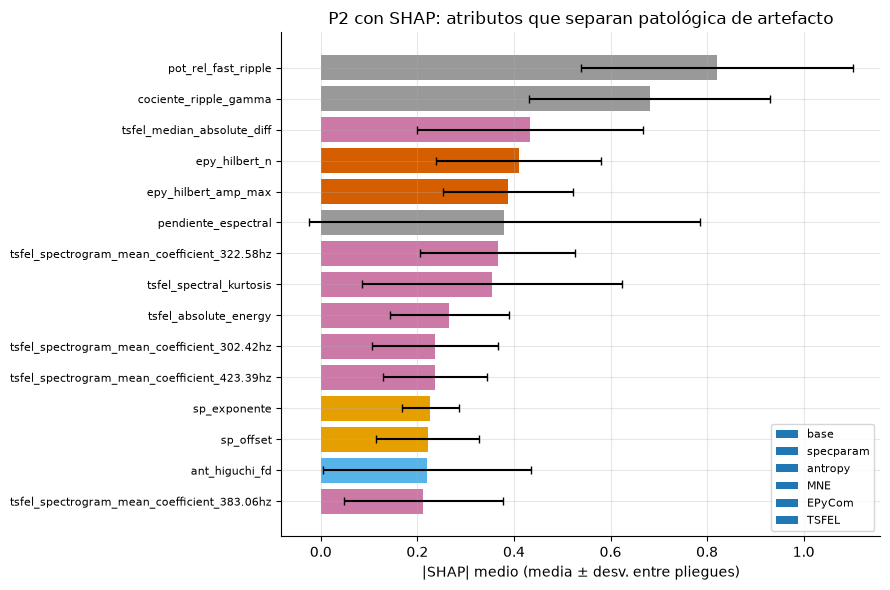

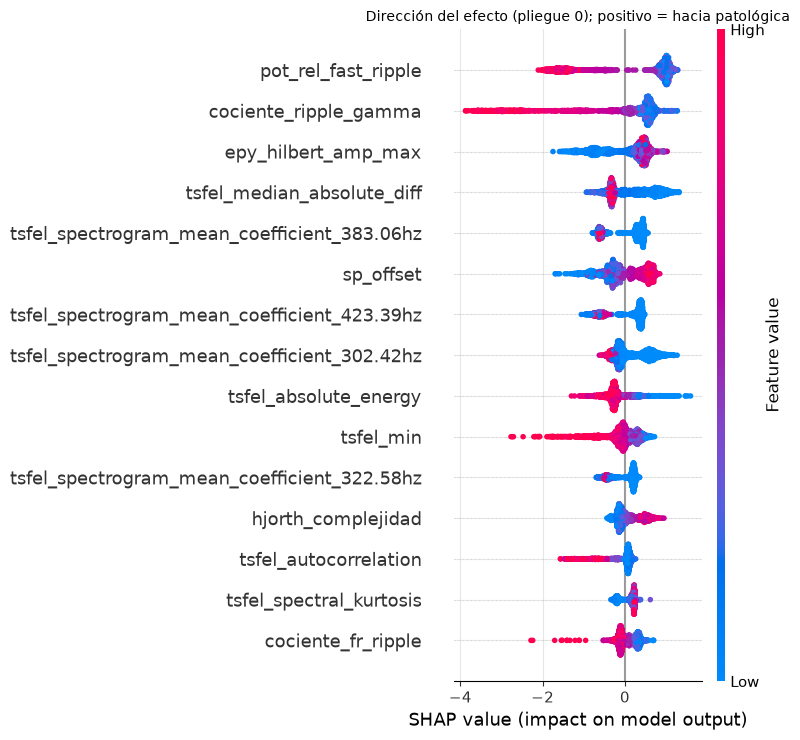

In [44]:
top_shap = ranking_shap.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(range(len(top_shap)), top_shap["|SHAP| medio"], xerr=top_shap["desv."], capsize=3,
        color=[COLOR_GRUPO[l] for l in top_shap["librería"]])
ax.set_yticks(range(len(top_shap)), top_shap.index, fontsize=8)
ax.set_xlabel("|SHAP| medio (media ± desv. entre pliegues)")
ax.set_title("P2 con SHAP: atributos que separan patológica de artefacto")
for grupo, color in COLOR_GRUPO.items():
    ax.barh([], [], color=color, label=grupo)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURAS / "p2_shap_importancia.png", dpi=150, bbox_inches="tight")
plt.show()

valores, Xm_shap, pl = guardado_shap
shap.summary_plot(valores, Xm_shap, feature_names=COLS_SHAP, max_display=15, show=False)
plt.title(f"Dirección del efecto (pliegue {pl}); positivo = hacia patológica", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURAS / "p2_shap_direccion.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura.**

- **Los atributos nuevos no mejoran la separación entre patológica y artefacto:** F1 de 0.889 ± 0.068, igual que el *gradient boosting* binario de P2 (sección 6; 0.886 ± 0.073) con solo los 30 atributos.
- **SHAP confirma la respuesta a P2 con otro método.** Los dos atributos más importantes son la **potencia relativa en *fast ripple*** (1.º, en el top 10 de los 5 pliegues) y el **cociente *ripple*/gamma** (2.º, también en los 5), los mismos que encontró la importancia por permutación; la pendiente espectral queda 6.ª.
- **La dirección es coherente con la fisiología.** Mucha energía relativa en *fast ripple* y un cociente *ripple*/gamma alto empujan hacia **artefacto** (la actividad muscular tiene energía de banda ancha en alta frecuencia); una **amplitud alta del detector de Hilbert** de EPyCom empuja hacia **patológica** (las HFOs son ráfagas breves y de gran amplitud relativa).
- **Lo nuevo:** el número y la amplitud máxima de los eventos del detector de Hilbert (EPyCom) quedan 4.º y 5.º, y la diferencia absoluta mediana de TSFEL, 3.ª. Un detector publicado de HFOs aporta información útil, aunque redundante con los 30 originales (8.3).
- **El ranking de SHAP es estable** (Spearman medio 0.83, mínimo 0.75), mucho más que el de permutación de P2 (0.38). Parte de la diferencia puede venir del método y parte de que aquí hay más atributos y otro conjunto de fragmentos, así que no es una comparación directa.
- Por librería, TSFEL suma la mayor importancia (6.1), pero repartida en 156 atributos (~0.04 cada uno); los 30 originales suman 3.6 (~0.12 cada uno).

### 8.6 Redes publicadas para EEG con braindecode

La CNN de la sección 7 es una arquitectura propia. Aquí se prueban tres redes publicadas, implementadas en **braindecode**, sobre la misma señal (1250 Hz, 3750 muestras, normalizada por fragmento), con los **mismos pliegues** y el mismo entrenamiento que la CNN: 15 épocas, Adam (tasa 1e-3), lotes de 128 y pesos por clase, sin parada temprana.

| Red | Idea | Parámetros |
|---|---|---|
| **ShallowFBCSPNet** | Imita un banco de filtros: convolución temporal, potencia y promedio | ~42 mil |
| **EEGNet** | Convoluciones separables, muy compacta | ~9 mil |
| **Deep4Net** | Cuatro bloques convolucionales, la más profunda | ~297 mil |

Las redes que se entrenan se eligen en `REDES_BD`. Si `resultados/braindecode_predicciones.csv` ya tiene sus predicciones, se cargan sin volver a entrenar. Si no, se entrenan con GPU o, con `BD_EN_CPU = True`, en el procesador. **En esta ejecución solo se entrenó EEGNet, en CPU:** se agotaron las unidades de GPU de Colab, y en el procesador ShallowFBCSPNet tardaría ~2 h y Deep4Net ~6 h, más de lo que permitía la fecha de entrega. Con GPU basta con agregarlas a `REDES_BD`.

In [45]:
RUTA_BD = RESULTADOS / "braindecode_predicciones.csv"
try:
    import torch
    import braindecode
    import braindecode.models as bm
    HAY_TORCH = True
    HAY_GPU = torch.cuda.is_available()
    print(f"torch {torch.__version__} | braindecode {braindecode.__version__} | GPU: {HAY_GPU}")
except ImportError:
    HAY_TORCH = HAY_GPU = False
    print("torch o braindecode no están instalados.")
previas_bd = pd.read_csv(RUTA_BD) if RUTA_BD.exists() else None
GUARDADAS_BD = previas_bd is not None and all(f"pred_{r}" in previas_bd for r in REDES_BD)
ENTRENAR_BD = HAY_TORCH and (HAY_GPU or BD_EN_CPU or PRUEBA_RAPIDA) and (PRUEBA_RAPIDA or not GUARDADAS_BD)
print("Redes:", REDES_BD, "| predicciones guardadas:", GUARDADAS_BD, "| se entrenan:", ENTRENAR_BD,
      "| dispositivo:", "GPU" if HAY_GPU else "CPU")

torch 2.15.0+cpu | braindecode 2.1.0 | GPU: False
Redes: ['EEGNet'] | predicciones guardadas: False | se entrenan: True | dispositivo: CPU


In [46]:
REDES = {
    "ShallowFBCSPNet": lambda: bm.ShallowFBCSPNet(n_chans=1, n_outputs=4, n_times=3750, sfreq=1250),
    "EEGNet": lambda: getattr(bm, "EEGNet", getattr(bm, "EEGNetv4", None))(n_chans=1, n_outputs=4, n_times=3750, sfreq=1250),
    "Deep4Net": lambda: bm.Deep4Net(n_chans=1, n_outputs=4, n_times=3750, sfreq=1250),
}


def entrenar_red(nombre, x_, y_, pliegue_):
    """Validación cruzada de una red de braindecode con los pliegues fijos. Devuelve la clase predicha."""
    dispositivo = "cuda" if HAY_GPU else "cpu"
    pred_ = np.empty(len(y_), dtype=int)
    for pl in np.unique(pliegue_):
        torch.manual_seed(SEMILLA + int(pl))
        entr, prueba = pliegue_ != pl, pliegue_ == pl
        pesos = compute_sample_weight("balanced", y_[entr])
        peso_clase = torch.tensor([pesos[y_[entr] == c][0] if (y_[entr] == c).any() else 0.0 for c in range(4)],
                                  dtype=torch.float32, device=dispositivo)
        red = REDES[nombre]().to(dispositivo)
        opt = torch.optim.Adam(red.parameters(), lr=1e-3)
        perdida = torch.nn.CrossEntropyLoss(weight=peso_clase)
        xe = torch.tensor(x_[entr], dtype=torch.float32)
        ye = torch.tensor(y_[entr], dtype=torch.long)
        t0 = time.time()
        red.train()
        for _ in range(EPOCAS_BD):
            orden = torch.randperm(len(ye))
            for i in range(0, len(ye), 128):
                lote = orden[i:i + 128]
                opt.zero_grad()
                valor = perdida(red(xe[lote].to(dispositivo)), ye[lote].to(dispositivo))
                valor.backward()
                opt.step()
        red.eval()
        xp = torch.tensor(x_[prueba], dtype=torch.float32)
        with torch.no_grad():
            pred_[prueba] = torch.cat([red(xp[i:i + 512].to(dispositivo)).argmax(1).cpu()
                                       for i in range(0, len(xp), 512)]).numpy()
        f1_k = f1_patologica(np.array(CLASES)[y_[prueba]], np.array(CLASES)[pred_[prueba]])
        print(f"  {nombre} pliegue {pl}: F1 patológica = {f1_k:.3f}  ({time.time() - t0:.0f} s)", flush=True)
    return pred_


if ENTRENAR_BD:
    sub_bd = np.load(DATOS / "cnn_subconjunto_fnusa.npz")
    sid_bd = sub_bd["segment_id"]
    en_dx = np.isin(sid_bd, dx["segment_id"])          # en PRUEBA_RAPIDA, solo los fragmentos de dx
    x_bd = sub_bd["x"][en_dx].astype(np.float32)
    x_bd = ((x_bd - x_bd.mean(axis=1, keepdims=True)) / (x_bd.std(axis=1, keepdims=True) + 1e-6))[:, np.newaxis, :]
    y_bd = np.array([CLASES.index(MAPA_CLASES[c]) for c in sub_bd["y"][en_dx]])
    k_bd = sub_bd["pliegue"][en_dx]
    pred_bd = pd.DataFrame({"segment_id": sid_bd[en_dx], "pliegue": k_bd, "real": np.array(CLASES)[y_bd]})
    for nombre in REDES_BD:
        t0 = time.time()
        pred_bd[f"pred_{nombre}"] = np.array(CLASES)[entrenar_red(nombre, x_bd, y_bd, k_bd)]
        print(f"{nombre}: {(time.time() - t0) / 60:.1f} min")
        if not PRUEBA_RAPIDA:                         # se guarda después de cada red, por si se interrumpe
            pred_bd.to_csv(RUTA_BD, index=False)
    if not PRUEBA_RAPIDA:
        print("Predicciones guardadas en", RUTA_BD)
elif GUARDADAS_BD:
    pred_bd = previas_bd
    print("Se cargan las predicciones guardadas:", RUTA_BD)
else:
    pred_bd = None
    print("Sin GPU ni predicciones guardadas (y BD_EN_CPU = False): ver README.")

  EEGNet pliegue 0: F1 patológica = 0.575  (551 s)


  EEGNet pliegue 1: F1 patológica = 0.653  (778 s)


  EEGNet pliegue 2: F1 patológica = 0.361  (719 s)


  EEGNet pliegue 3: F1 patológica = 0.921  (667 s)


  EEGNet pliegue 4: F1 patológica = 0.547  (562 s)


EEGNet: 54.8 min


Predicciones guardadas en resultados\braindecode_predicciones.csv


**Comparación con el SVM de atributos y con la CNN de la sección 7.** Las tres redes, la CNN propia (si están sus predicciones en `resultados/cnn_predicciones.csv`) y el mejor modelo de atributos de 8.2 se comparan sobre los mismos fragmentos y pliegues.

In [47]:
if pred_bd is not None:
    comun = dx[["segment_id"]].assign(fila=np.arange(len(dx))).merge(pred_bd, on="segment_id")
    filas_bd = comun["fila"].to_numpy()
    y_c, g_c, k_c = y_x[filas_bd], g_x[filas_bd], k_x[filas_bd]
    preds_bd = {REFERENCIA: res_x[REFERENCIA]["pred"][filas_bd]}
    mejor_atr = tabla_x.drop(REFERENCIA)["F1 pat. (media)"].idxmax()
    preds_bd[mejor_atr] = res_x[mejor_atr]["pred"][filas_bd]
    ruta_cnn = RESULTADOS / "cnn_predicciones.csv"
    if ruta_cnn.exists():
        cnn_pred = pd.read_csv(ruta_cnn).set_index("segment_id")["pred"].map(lambda c: MAPA_CLASES.get(c, c))
        preds_bd["CNN propia (sección 7)"] = cnn_pred.reindex(comun["segment_id"]).to_numpy()
    for nombre in [c[len("pred_"):] for c in pred_bd.columns if c.startswith("pred_")]:
        preds_bd[nombre] = comun[f"pred_{nombre}"].to_numpy()
    boot_bd = bootstrap_pacientes(preds_bd, y_c, g_c)
    filas_t = []
    for nombre, p in preds_bd.items():
        f1k = np.array([f1_patologica(y_c[k_c == pl], p[k_c == pl]) for pl in np.unique(k_c)])
        d = boot_bd[nombre] - boot_bd[REFERENCIA]
        filas_t.append({"modelo": nombre, "F1 pat. (media)": f1k.mean(), "desv.": f1k.std(),
                        "F1 pat. global": f1_patologica(y_c, p),
                        "F1 macro global": f1_score(y_c, p, average="macro"),
                        "Δ global vs. ref.": f1_patologica(y_c, p) - f1_patologica(y_c, preds_bd[REFERENCIA]),
                        "IC 95 % Δ inf.": np.percentile(d, 2.5), "IC 95 % Δ sup.": np.percentile(d, 97.5)})
    tabla_bd = pd.DataFrame(filas_t).set_index("modelo").round(3)
    if not PRUEBA_RAPIDA:
        tabla_bd.to_csv(RESULTADOS / "ext_braindecode.csv")
    display(tabla_bd)
else:
    print("Sin predicciones de braindecode.")

,F1 pat. (media),desv.,F1 pat. global,F1 macro global,Δ global vs. ref.,IC 95 % Δ inf.,IC 95 % Δ sup.
modelo,,,,,,,
SVM · base (30),0.720,0.177,0.694,0.692,0.000,0.000,0.000
SVM · base + nuevos,0.751,0.180,0.731,0.700,0.037,0.023,0.052
CNN propia (sección 7),0.759,0.101,0.770,0.649,0.076,-0.006,0.157
EEGNet,0.611,0.182,0.629,0.668,-0.064,-0.186,0.069


**Lectura.**

- **EEGNet queda por debajo del SVM, pero sin diferencia clara:** F1 patológica de 0.61 ± 0.18 (global 0.63) frente a 0.72 ± 0.18 (global 0.69); la diferencia global es de −0.064, con IC 95 % de −0.186 a +0.069, que incluye el 0. Varía mucho entre pliegues (de 0.36 a 0.92), igual que los demás modelos.
- **En la F1 macro sacrifica menos las otras clases** que la CNN propia: 0.67, cerca del SVM (0.69).
- **Las predicciones guardadas de la CNN vienen de otra ejecución.** El archivo `resultados/cnn_predicciones.csv` usado en esta tabla da a la CNN 0.76 ± 0.10 (global 0.77), mientras que la ejecución que muestra la sección 7.5 da 0.72 ± 0.17 (global 0.69). El reporte usa las cifras de la sección 7.5. Que dos ejecuciones de la misma red difieran ~0.04 (el entrenamiento en GPU no es determinista) es del mismo orden que las diferencias entre modelos.
- **Solo se evaluó una red publicada, en CPU y con 15 épocas** (ver las restricciones de la sección 9): no se puede concluir que las redes publicadas no sirvan para este problema.

## 9. Conclusiones

Las cifras de esta sección corresponden a la ejecución de este notebook (secciones 5 a 8). Si se vuelve a ejecutar con otras versiones de las librerías, conviene confirmarlas contra las salidas.

**P1. Sí: los atributos bastan para superar a las líneas base en la detección de actividad patológica, con un desempeño moderado.** El mejor modelo, un SVM con kernel RBF, obtiene un F1 patológica de 0.72 ± 0.17 entre pliegues (0.70 sobre todas las predicciones fuera de pliegue, IC 95 % por *bootstrap* de pacientes 0.53–0.84), con sensibilidad de 0.78 y precisión de 0.63. La regla de umbrales llega a 0.55 y la clase mayoritaria a 0. La mejora sobre la regla es de +0.15, con un intervalo que apenas excluye el cero (+0.01 a +0.27), y se da en 4 de 5 pliegues. El random forest empata con el SVM (diferencia −0.001). Ajustando sus hiperparámetros con validación anidada (sección 5.4), el SVM llega a 0.74 ± 0.17 (global 0.71), una mejora pequeña pero consistente, que viene de una frontera más suave. Los demás modelos quedan entre 0.64 y 0.69, diferencias menores que la variabilidad entre pliegues: con 14 pacientes, **el paciente pesa más que el algoritmo**. El gradient boosting y el árbol de decisión quedan al fondo, lo que sugiere que aprenden detalles propios de los pacientes de entrenamiento. En el F1 macro (secundaria), el SVM también es el mejor (0.62).

**P2. La potencia relativa en *fast ripple* es el atributo clave para separar lo patológico de los artefactos**: está en el top 5 de los cinco pliegues y es primera o segunda con los tres métodos de importancia. Le siguen la pendiente espectral y el cociente *ripple*/gamma. El ranking completo es poco estable (Spearman = 0.38), pero sus primeros puestos sí lo son.

**P3. La generalización entre hospitales es asimétrica.** Entrenado en FNUSA, el F1 patológica cae de 0.70 a 0.49 en Mayo: la sensibilidad se mantiene (0.86) pero aumentan las falsas alarmas. Entrenado en Mayo, que tiene más pacientes, alcanza 0.76 en FNUSA, más que la validación dentro de FNUSA. Entrenar con más pacientes importa más que el algoritmo.

**Deep learning.** La red neuronal MLP sobre los atributos (F1 patológica 0.69 ± 0.18) queda al nivel de la regresión logística, sin superar al SVM: con atributos ya diseñados, una red pequeña no aporta más que los modelos clásicos. La CNN 1D sobre la señal cruda empata con el SVM en la clase patológica en el mismo subconjunto (0.72 ± 0.17 frente a 0.72 ± 0.18; diferencia global de 0.000, IC 95 % por *bootstrap* de pacientes: −0.045 a +0.035) y gana en 4 de 5 pliegues por poco, pero es claramente peor en las demás clases (F1 macro global de 0.55 frente a 0.69): aprende sola lo patológico, no el resto.

**Extensiones (sección 8).** En el mismo subconjunto, 196 atributos de librerías especializadas suben al SVM de 0.72 a 0.75 (+0.037 global, IC 95 %: +0.023 a +0.052, mejor en los 5 pliegues), con menos falsas alarmas; un tercio de esa mejora viene de transformar los atributos por cuantiles y casi todo el aporte de los atributos nuevos viene de TSFEL. LightGBM, XGBoost y optuna no superan al SVM (0.74): con 3 o 4 pacientes por pliegue interno, la validación interna no predice el desempeño en pacientes nuevos. SHAP confirma P2 (*fast ripple* y el cociente *ripple*/gamma primero, con un ranking estable) y agrega el detector de HFO de Hilbert de EPyCom, cuya amplitud empuja hacia *patológica*. EEGNet (8.6), la única red de braindecode que se pudo entrenar (en CPU, por falta de GPU), obtiene 0.61 ± 0.18 de F1 patológica, sin diferencia clara con el SVM (−0.064; IC 95 %: −0.186 a +0.069).

**Limitaciones.** Solo 14 pacientes en FNUSA y 24 en Mayo, con la clase muy ligada al paciente; las señales vienen normalizadas, así que se perdió la amplitud absoluta; los hiperparámetros solo se ajustaron para el SVM y el gradient boosting, con una rejilla pequeña; kNN y SVM se entrenaron con submuestras; la CNN y la sección 8 usan solo el 21 % de FNUSA (los atributos de la sección 8, además, a 1250 Hz); la sección 8 suma muchas comparaciones sin corrección por comparaciones múltiples.

**Trabajo futuro.** Ampliar la búsqueda de hiperparámetros (la validación anidada ya mejoró al SVM y al gradient boosting), elegir el umbral de la clase patológica según el costo clínico de las falsas alarmas (con un umbral elegido solo por F1 no hubo mejora), combinar atributos y CNN, y entrenar con ambos hospitales.

### Restricciones de tiempo y cómputo

El proyecto se hizo con recursos limitados: Google Colab con una GPU T4 y unidades de cómputo limitadas (secciones 1 a 7) y una computadora personal con un i7-13620H de 16 hilos y 16 GB de RAM (sección 8, porque las unidades de GPU de Colab se agotaron). Esa computadora tiene una GPU RTX 4050, pero no hubo tiempo de configurar PyTorch con CUDA antes de la entrega, así que la sección 8 corrió en el procesador. **Las salidas de este notebook vienen de esas dos ejecuciones**; las versiones de las librerías se imprimen en la sección 0 (Colab) y al inicio de la sección 8 (computadora personal). Varias decisiones responden a esos límites:

| Restricción | Por qué | Costo medido o estimado | Efecto en los resultados |
|---|---|---|---|
| kNN y SVM se entrenan con submuestras estratificadas de 20 y 10 mil fragmentos por pliegue | Su costo crece con el cuadrado del número de ejemplos | Con la submuestra, la validación del SVM tarda ~1 min (sección 4.3) | Un SVM con todos los datos podría rendir algo distinto; con 30 mil fragmentos no mejoró (sección 5.4) |
| Hiperparámetros fijados de antemano; validación anidada solo para el SVM y el *gradient boosting*, con rejillas pequeñas | Cada validación anidada multiplica el número de ajustes | ~2 h (`scripts/experimentos_mejora.py`) | Los otros modelos no se ajustaron; la sección 8.4 sugiere que ajustar ayuda poco |
| Importancia por permutación (P2) con *gradient boosting*, en hasta 8,000 fragmentos de prueba por pliegue y 5 repeticiones; información mutua y L1 con 20,000 fragmentos | La permutación requiere cientos de predicciones por pliegue y el SVM es demasiado lento | — | El ranking es el de ese modelo, no el del SVM |
| La CNN y toda la sección 8 usan el subconjunto del 21 % de FNUSA a 1250 Hz | El archivo de señales baja a ~300 MB, manejable en Colab, y los atributos adicionales son costosos | CNN: ~9 min en la T4. Atributos adicionales: 100 min con 14 procesos en el subconjunto; en los 348 mil fragmentos a 5 kHz se estimó (midiendo 200 fragmentos) ~30 h solo para TSFEL y ~140 h para el detector de Hilbert en Colab | No responde P3; sin la banda de 600–1000 Hz |
| TSFEL sin el dominio fractal | ~7 s por fragmento | ~80 h para el subconjunto con un proceso | Se pierden atributos fractales de TSFEL (antropy aporta Higuchi, Katz, Petrosian y DFA) |
| optuna con 25 intentos por pliegue externo y 3 pliegues internos | Cada intento son 3 ajustes de LightGBM | ~13 min con 16 hilos | Búsqueda acotada; de todos modos, la F1 interna no predijo la externa |
| SHAP sobre hasta 2,000 fragmentos de prueba por pliegue | Tiempo de cálculo | ~17 s por cada 2,000 fragmentos con 30 atributos (medido); más con los 226 | El ranking resultó estable (Spearman 0.83) |
| CNN propia: una sola arquitectura y 15 épocas fijas | Unidades de GPU limitadas | ~9 min en la T4 | No se puede concluir que el *deep learning* no sirva |
| braindecode (8.6): solo EEGNet, entrenada en CPU, 15 épocas | Se agotaron las unidades de GPU de Colab y la entrega tenía fecha límite | EEGNet: 55 min en CPU. Medido con 2,000 fragmentos: ShallowFBCSPNet ~2 h y Deep4Net ~6 h en CPU, por eso no se entrenaron | Solo una de las tres redes publicadas quedó evaluada |

---
**Declaración de uso de IA generativa.** Se utilizó el asistente de inteligencia artificial Claude (Anthropic) en la elaboración de este notebook. La autora revisó el contenido y es responsable de su exactitud.